In [1]:
import numpy as np
from scipy.io import loadmat
import warnings
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit

In [2]:
!pip install pandas
!pip install resonator_tools

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root, least_squares
from scipy.special import ellipk
from scipy.constants import mu_0, epsilon_0
from resonator_tools import circuit

In [4]:
# Files
File_Complex     = 'S21_corr_complex_v2.mat'
FILE_FREQ        = 'Freq.mat'
FILE_CURRENT     = 'I1.mat'
File_F0_Guess    = 'f0_guess_v4.mat'

def mat_to_1d_vector(d):
    for k, v in d.items():
        if k.startswith('__'): continue
        arr = np.asarray(v).squeeze()
        if arr.ndim == 1 and np.isrealobj(arr):
            return arr
    raise ValueError("No 1D array found in .mat file")

Mat_Freq     = loadmat(FILE_FREQ, squeeze_me=True)
Mat_Current  = loadmat(FILE_CURRENT, squeeze_me=True)
Mat_Complex  = loadmat(File_Complex, squeeze_me=True)
Mat_F0_Guess = loadmat(File_F0_Guess, squeeze_me=True)
S21_Complex_full = Mat_Complex['S21_corrected'] 
Freq = Mat_Freq['Freq_lp']
I1_full  = Mat_Current['I1']
f0_guess = Mat_F0_Guess['dips']
#Mat_Complex

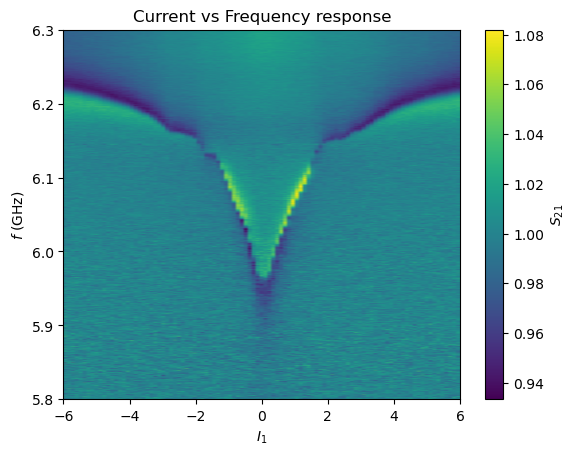

In [5]:
plt.imshow(np.abs(S21_Complex_full), aspect='auto', origin='lower', extent=[I1_full[0], I1_full[-1], Freq[0]/1e9, Freq[-1]/1e9])
plt.colorbar(label=r'$S_{21}$')
plt.xlabel(r'$I_1$')
plt.ylabel(r'$f$ (GHz)')
plt.title(r'Current vs Frequency response')
plt.show()

In [6]:
def fit_notch_trace(freq, z_complex, electric_delay_guess=None):
    """
    Fit one current trace using resonator_tools' notch (through-line) model.
    Returns (results_dict, (f_sorted, z_sorted, port)).
    """
    order = np.argsort(freq)
    f = np.asarray(freq)[order]
    z = np.asarray(z_complex)[order]
    port = circuit.notch_port()
    port.add_data(f, z)

    # Fit
    try:
        if electric_delay_guess is not None:
            port.autofit(electric_delay=electric_delay_guess)
        else:
            port.autofit()
    except Exception:
        # fallback for older versions
        port.fit()

    resdict = getattr(port, 'fitresults', None)
    if resdict is None:
        resdict = getattr(port, 'results', None)

    def get_d(keys):
        if isinstance(resdict, dict):
            for k in keys:
                if k in resdict:
                    v = np.asarray(resdict[k]).squeeze()
                    if v.size == 1:
                        return v.item()
        return None

    def get_a(keys):
        for k in keys:
            if hasattr(port, k):
                v = np.asarray(getattr(port, k)).squeeze()
                if v.size == 1:
                    return v.item()
        return None

    f0 = get_d(('fr','f0','fr_fit')) or get_a(('fr','f0','fr_fit'))
    Ql = get_d(('Ql','Q','Q_loaded')) or get_a(('Ql','Q','Q_loaded'))
    # Use the corrected internal Q if available
    Qi = get_d(('Qi_dia_corr','Qi','Qi_no_corr')) or get_a(('Qi_dia_corr','Qi','Qi_no_corr'))
    # External Q: prefer diameter-corrected if provided, else absQc
    Qc = get_d(('Qc_dia_corr','absQc')) or get_a(('Qc_dia_corr','absQc'))
    # Asymmetry angle and baseline phase
    phi = get_d(('phi0','phi')) or get_a(('phi0','phi'))
    delay = get_d(('delay','electrical_delay')) or get_a(('delay','electrical_delay'))

    # If Qi missing but Ql and Qc present, compute fallback (real-coupling assumption)
    if (Qi is None) and (Ql is not None) and (Qc is not None) and (Qc > Ql):
        Qi = (Ql * Qc) / (Qc - Ql)

    out = dict(
        f0=(float(f0) if f0 is not None and np.isfinite(f0) else None),
        Ql=(float(Ql) if Ql is not None and np.isfinite(Ql) else None),
        Qi=(float(Qi) if Qi is not None and np.isfinite(Qi) else None),
        Qc=(float(Qc) if Qc is not None and np.isfinite(Qc) else None),
        phi=(float(phi) if phi is not None and np.isfinite(phi) else np.nan),
        delay=(float(delay) if delay is not None and np.isfinite(delay) else np.nan),
        npoints=len(freq),
    )
    return out, (np.asarray(freq), np.asarray(z_complex), port)


In [130]:
from scipy.signal import medfilt
f0_smooth = medfilt(f0_guess, kernel_size=5)  # odd kernel; tune size
f0_smooth, f0_guess

(array([6.2260e+09, 6.2260e+09, 6.2260e+09, 6.2245e+09, 6.2230e+09,
        6.2230e+09, 6.2230e+09, 6.2190e+09, 6.2175e+09, 6.2155e+09,
        6.2125e+09, 6.2125e+09, 6.2105e+09, 6.2085e+09, 6.2070e+09,
        6.2060e+09, 6.2030e+09, 6.2015e+09, 6.1995e+09, 6.1990e+09,
        6.1945e+09, 6.1905e+09, 6.1890e+09, 6.1870e+09, 6.1820e+09,
        6.1770e+09, 6.1715e+09, 6.1685e+09, 6.1670e+09, 6.1660e+09,
        6.1625e+09, 6.1610e+09, 6.1595e+09, 6.1590e+09, 6.1590e+09,
        6.1440e+09, 6.1290e+09, 6.1290e+09, 6.1265e+09, 6.1195e+09,
        5.9975e+09, 5.9975e+09, 5.9975e+09, 6.0420e+09, 6.0420e+09,
        6.0420e+09, 6.0285e+09, 6.0000e+09, 5.9800e+09, 5.9555e+09,
        5.9555e+09, 5.9555e+09, 5.9595e+09, 5.9630e+09, 5.9825e+09,
        6.0045e+09, 6.0155e+09, 6.0155e+09, 6.0155e+09, 5.9660e+09,
        5.9270e+09, 5.8705e+09, 5.8705e+09, 5.8705e+09, 6.1350e+09,
        6.1410e+09, 6.1495e+09, 6.1515e+09, 6.1530e+09, 6.1535e+09,
        6.1535e+09, 6.1550e+09, 6.1580e+09, 6.16

In [7]:
fit_results_dict = {}
ports_dict = {}   # optional, if you want to re-plot a specific trace later without refitting
window_halfwidth = 199e6 
for i in range(S21_Complex_full.shape[1]):
    if i  > 39 and i <  65:
        window_halfwidth = 40e6
    else:
        window_halfwidth = 100e6
    mask = np.abs(Freq - f0_guess[i]) < window_halfwidth
    f_sub = Freq[mask]
    s_sub = S21_Complex_full[mask, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        port_i.autofit(electric_delay=0)
        fit_results_dict[i] = port_i.fitresults
        ports_dict[i] = port_i
    except Exception as e:
        print(f"I1={I1_full[i]:.3g} mA: fit failed ({e})")
        fit_results_dict[i] = None

# now this actually compares two different fits:
# print(20, fit_results_dict[20])
# print(21, fit_results_dict[21])
# print(22, fit_results_dict[22]) 

c:\Users\chowdhf4\.conda\envs\TwoQubitHeatValve\Lib\site-packages\resonator_tools\circlefit.py:157: RuntimeWarning: Number of calls to function has reached maxfev = 800.
  p_final = spopt.leastsq(
c:\Users\chowdhf4\.conda\envs\TwoQubitHeatValve\Lib\site-packages\resonator_tools\circlefit.py:130: RuntimeWarning: Number of calls to function has reached maxfev = 600.
  p_final = spopt.leastsq(


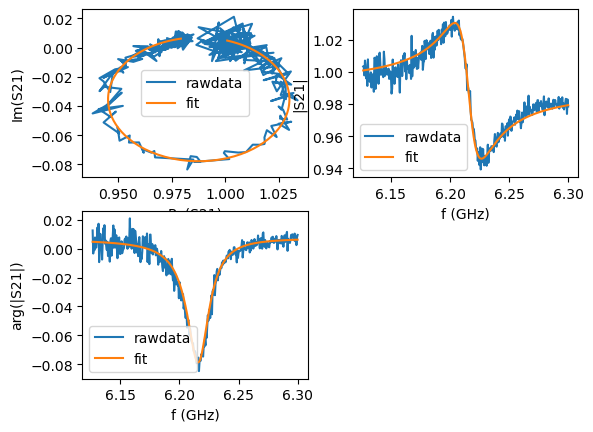

0
I1=-6 mA: f0=6215704744.007041 Hz, Ql=275


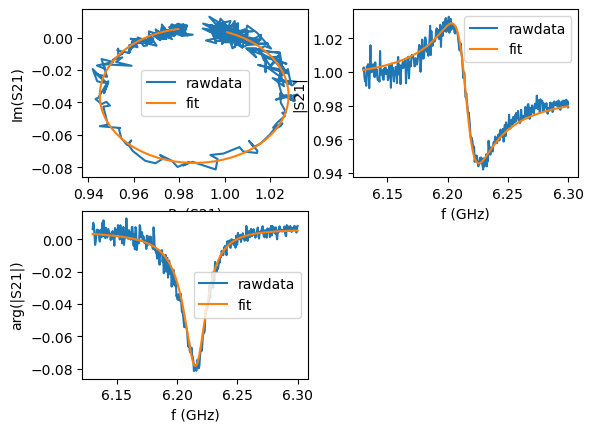

1
I1=-5.88 mA: f0=6215289882.655474 Hz, Ql=277


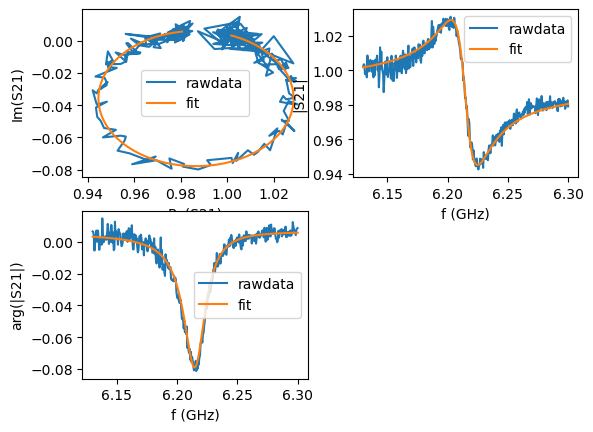

2
I1=-5.76 mA: f0=6214733840.247708 Hz, Ql=283


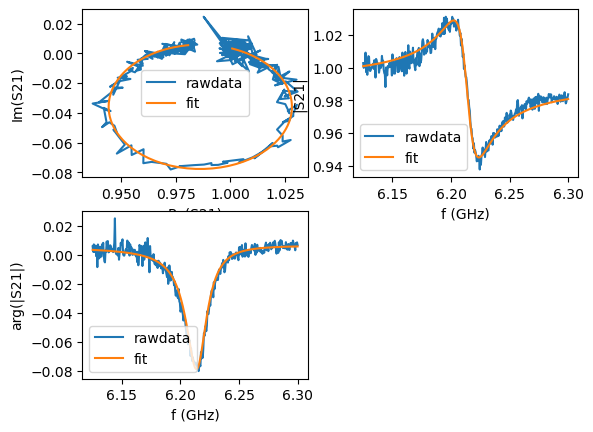

3
I1=-5.64 mA: f0=6213848312.462846 Hz, Ql=289


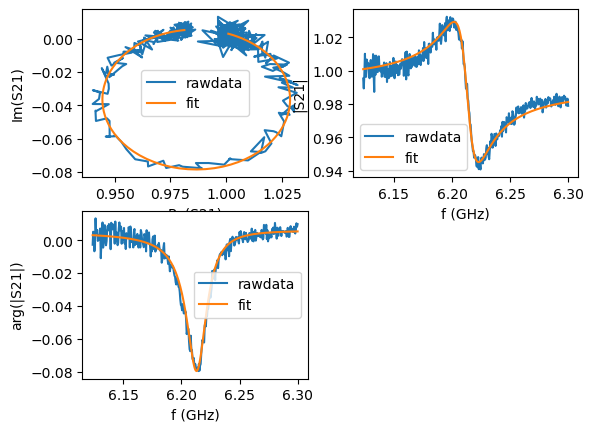

4
I1=-5.52 mA: f0=6213137532.520899 Hz, Ql=295


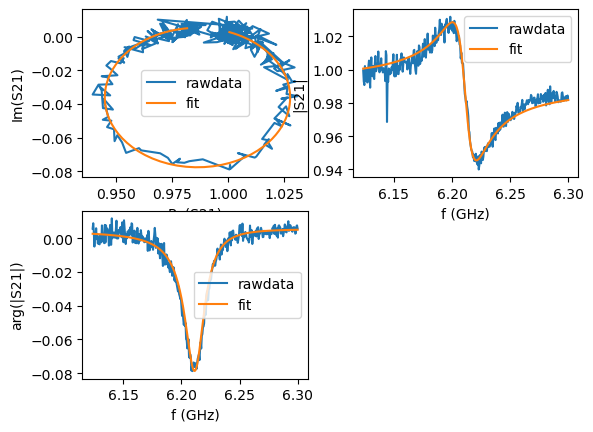

5
I1=-5.4 mA: f0=6211481948.581439 Hz, Ql=302


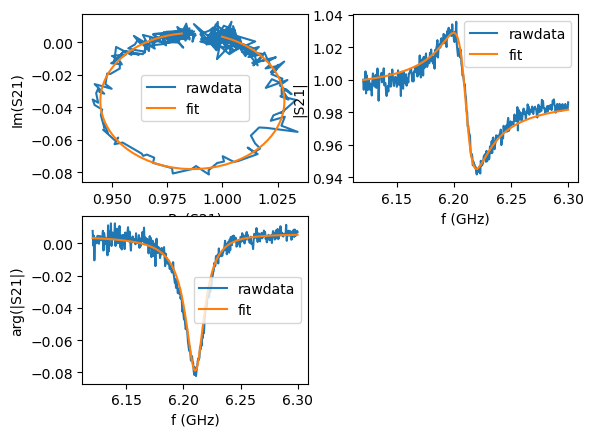

6
I1=-5.28 mA: f0=6210425093.069153 Hz, Ql=311


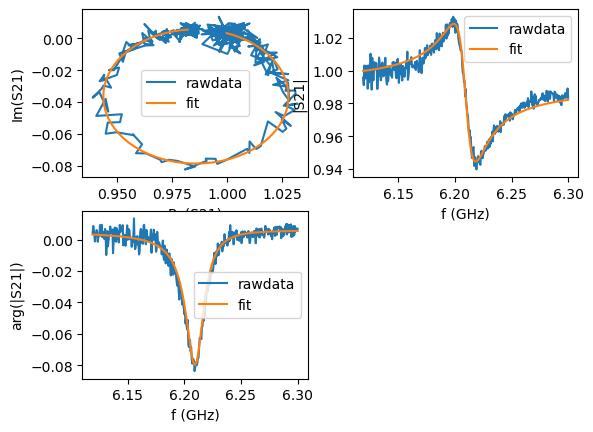

7
I1=-5.16 mA: f0=6209519890.087515 Hz, Ql=321


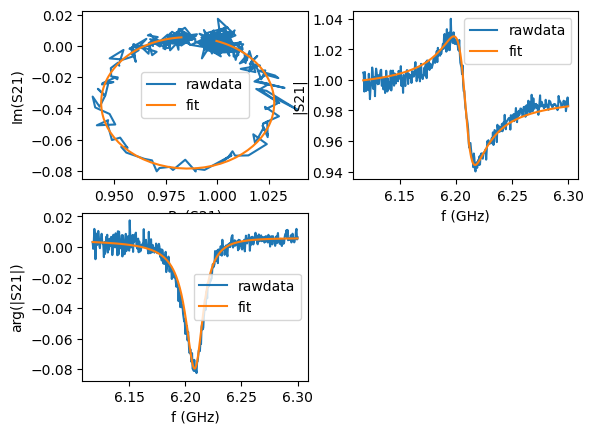

8
I1=-5.04 mA: f0=6208548237.988375 Hz, Ql=330


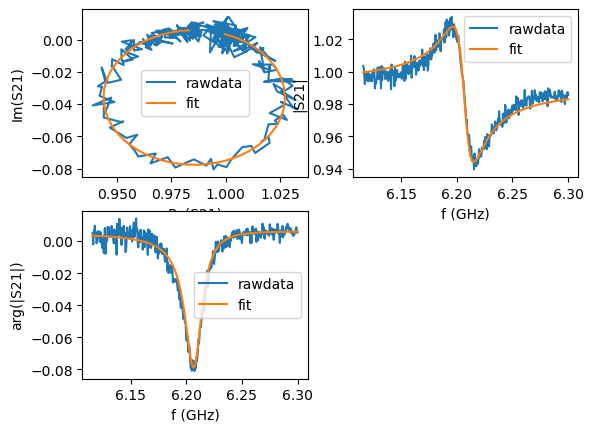

9
I1=-4.92 mA: f0=6206881768.548027 Hz, Ql=331


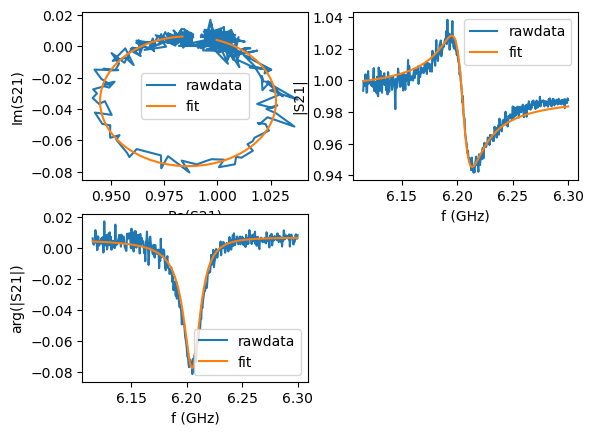

10
I1=-4.8 mA: f0=6205015840.963902 Hz, Ql=340


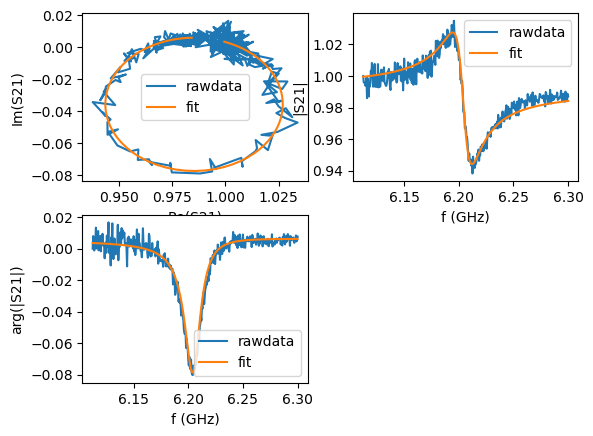

11
I1=-4.68 mA: f0=6204259683.510879 Hz, Ql=352


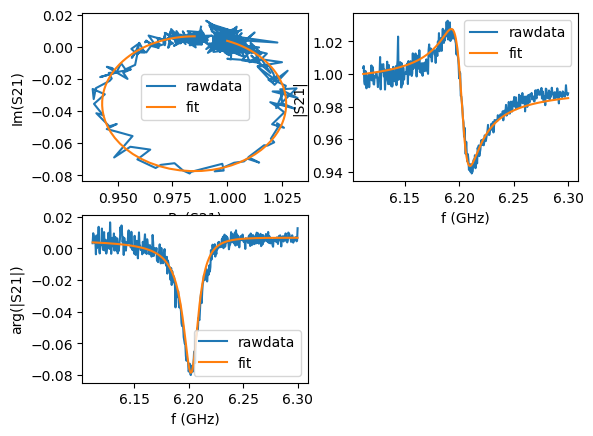

12
I1=-4.56 mA: f0=6202608756.775413 Hz, Ql=365


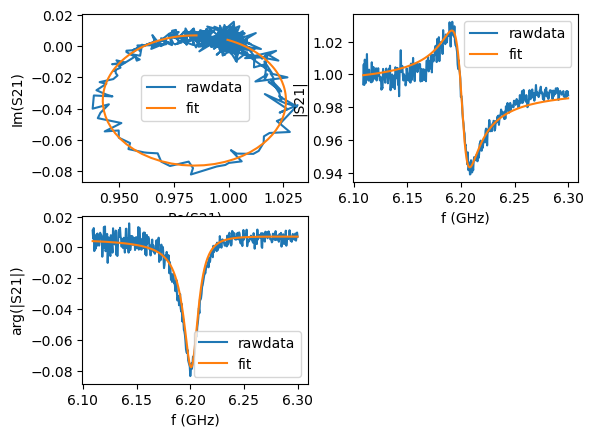

13
I1=-4.44 mA: f0=6201234604.086290 Hz, Ql=374


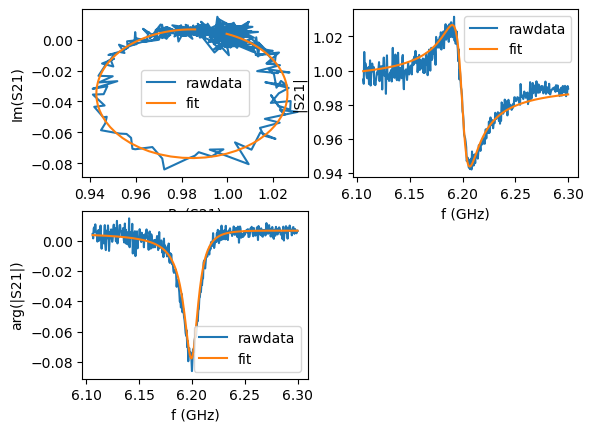

14
I1=-4.32 mA: f0=6199897751.023849 Hz, Ql=378


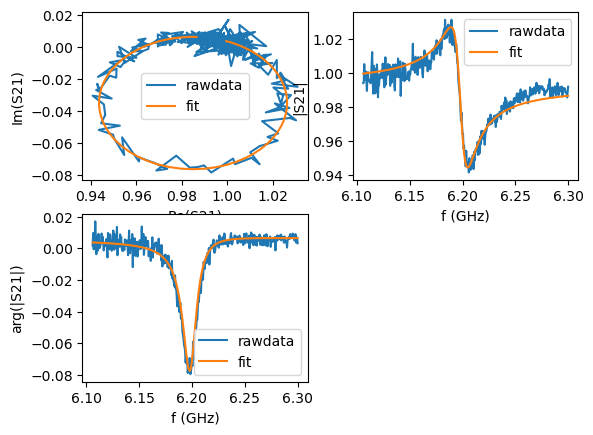

15
I1=-4.2 mA: f0=6198233115.916075 Hz, Ql=394


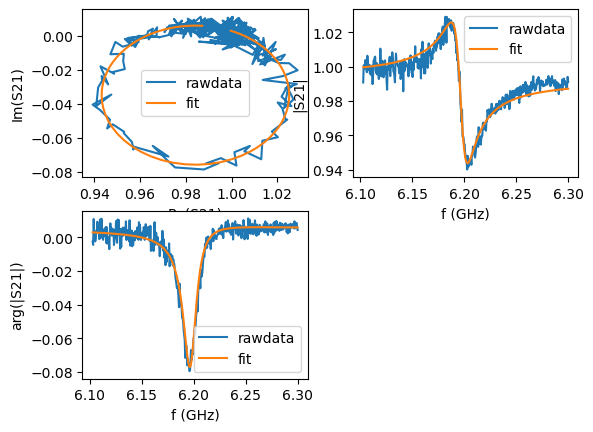

16
I1=-4.08 mA: f0=6196936701.516750 Hz, Ql=401


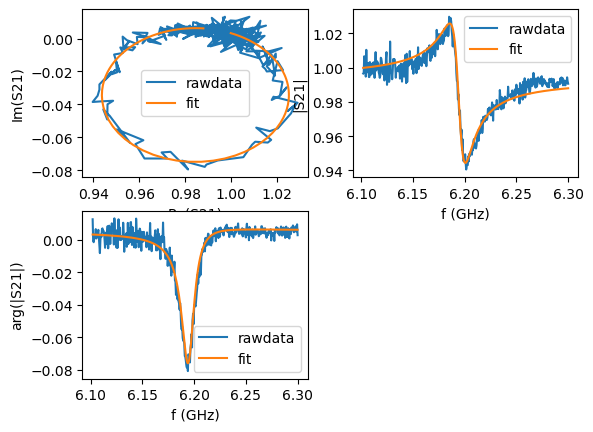

17
I1=-3.96 mA: f0=6194592873.512688 Hz, Ql=414


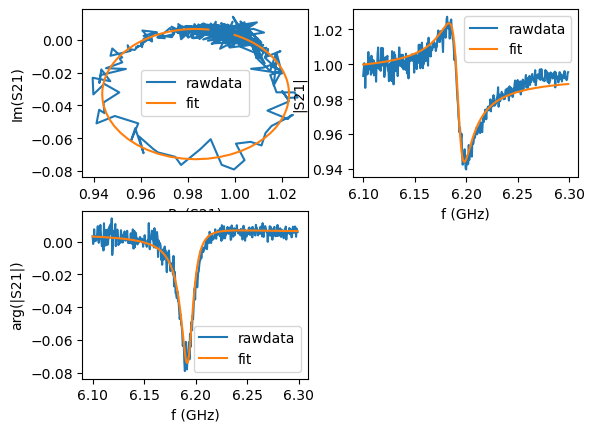

18
I1=-3.84 mA: f0=6192496420.916734 Hz, Ql=426


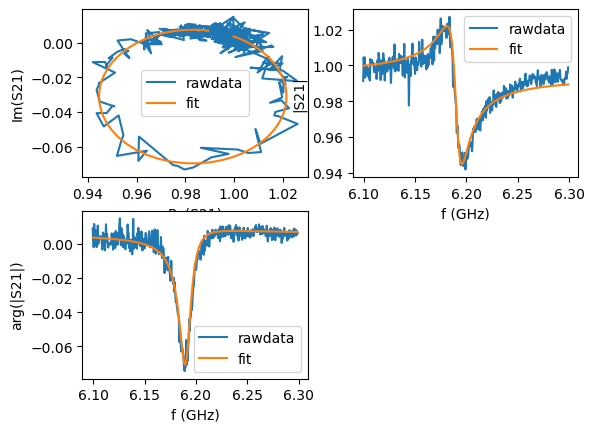

19
I1=-3.72 mA: f0=6190231667.360851 Hz, Ql=439


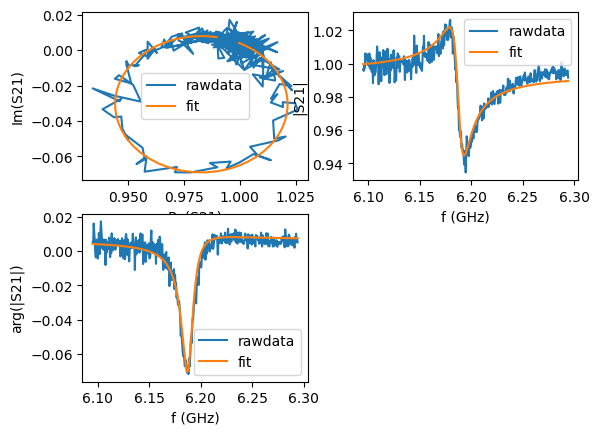

20
I1=-3.6 mA: f0=6187754524.392284 Hz, Ql=452


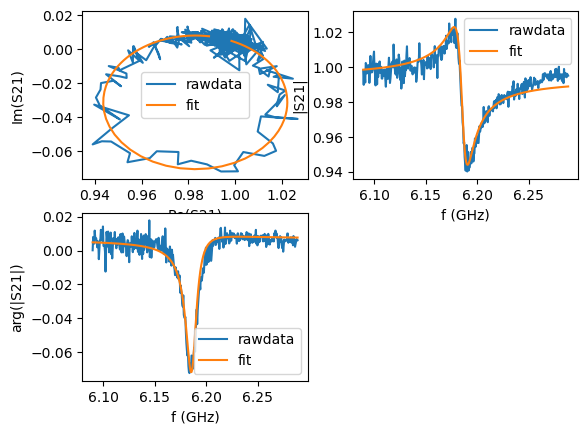

21
I1=-3.48 mA: f0=6185843614.821078 Hz, Ql=489


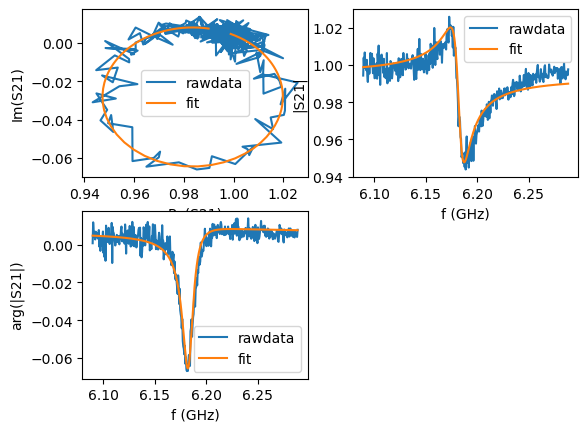

22
I1=-3.36 mA: f0=6182653646.686944 Hz, Ql=483


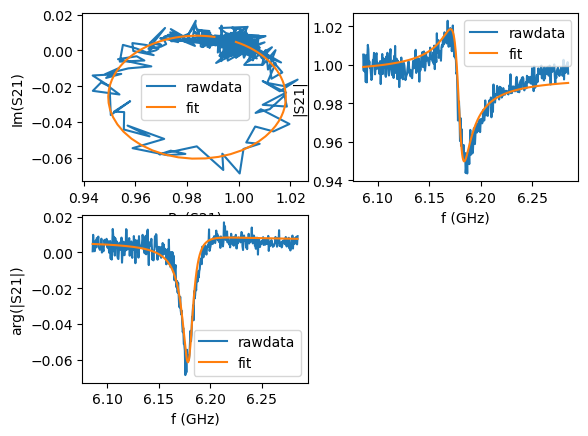

23
I1=-3.24 mA: f0=6179333589.434155 Hz, Ql=486


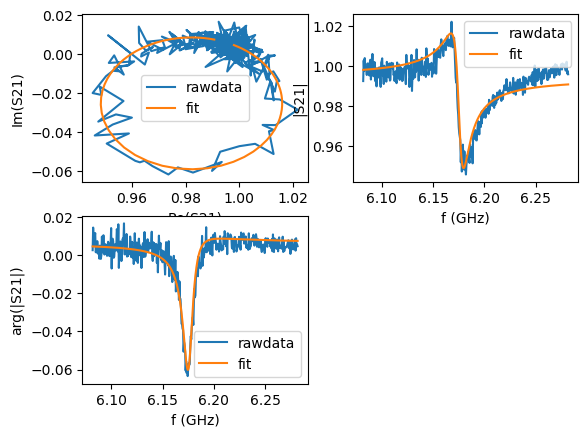

24
I1=-3.12 mA: f0=6175602832.431057 Hz, Ql=533


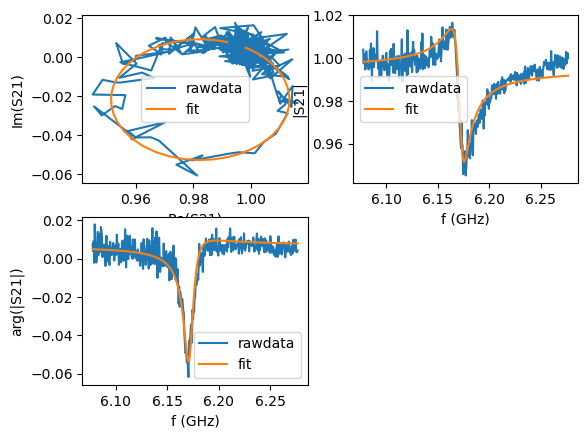

25
I1=-3 mA: f0=6171670214.789550 Hz, Ql=540


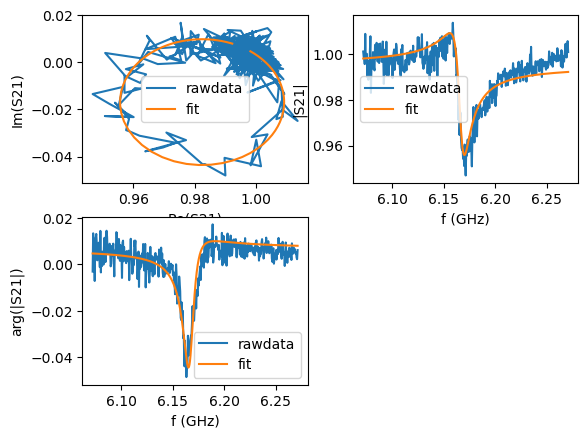

26
I1=-2.88 mA: f0=6166468054.462939 Hz, Ql=490


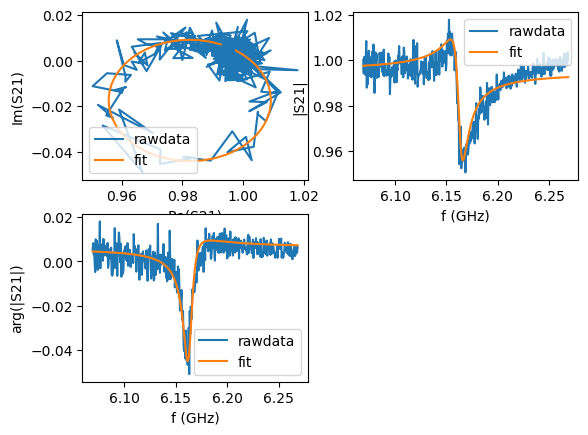

27
I1=-2.76 mA: f0=6162768550.027188 Hz, Ql=577


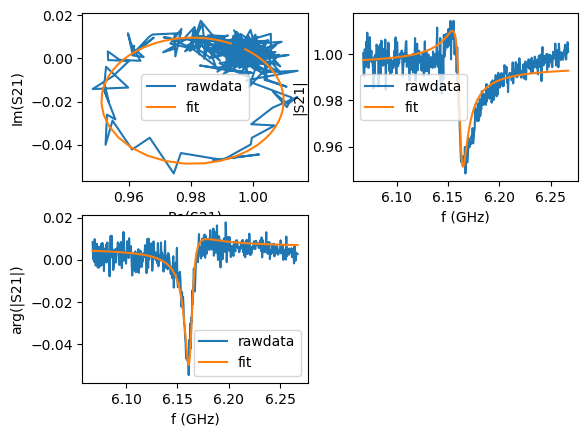

28
I1=-2.64 mA: f0=6162007282.298598 Hz, Ql=681


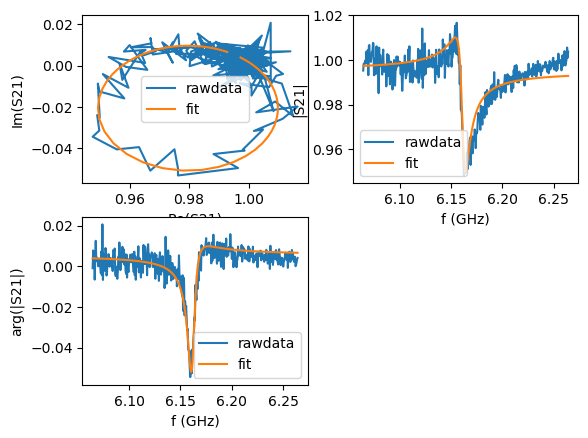

29
I1=-2.52 mA: f0=6161542826.983137 Hz, Ql=717


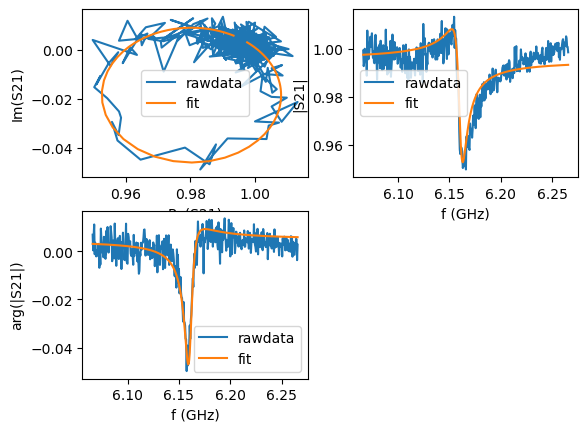

30
I1=-2.4 mA: f0=6160348491.133821 Hz, Ql=680


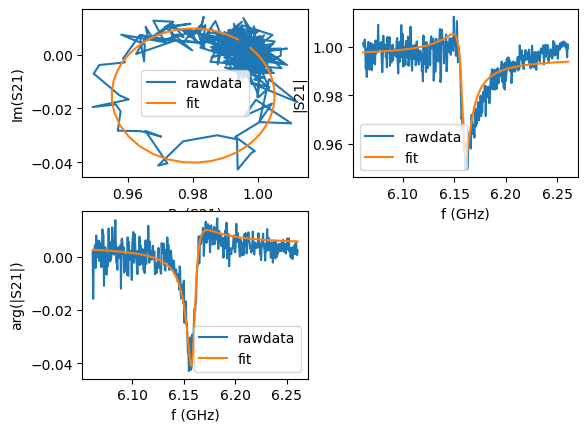

31
I1=-2.28 mA: f0=6158904776.826478 Hz, Ql=623


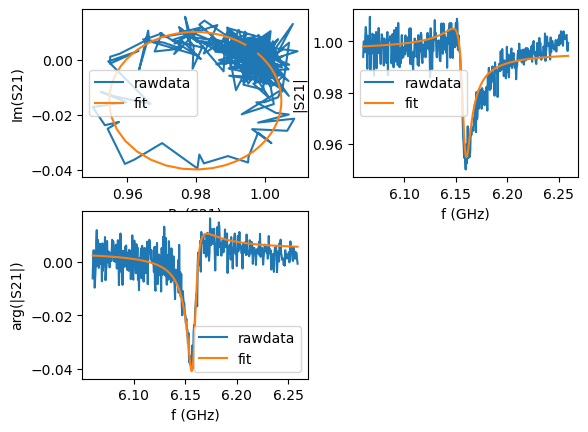

32
I1=-2.16 mA: f0=6157937203.146185 Hz, Ql=627


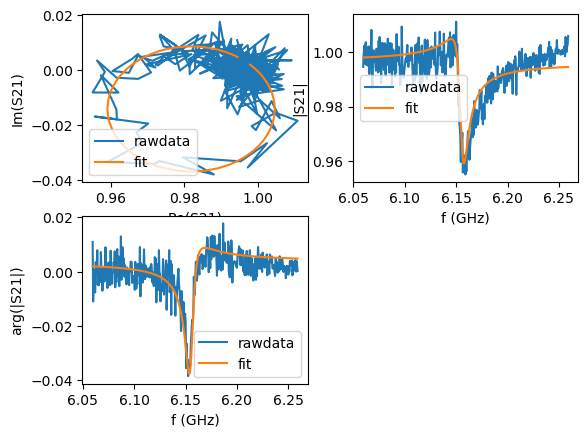

33
I1=-2.04 mA: f0=6155185692.745240 Hz, Ql=631


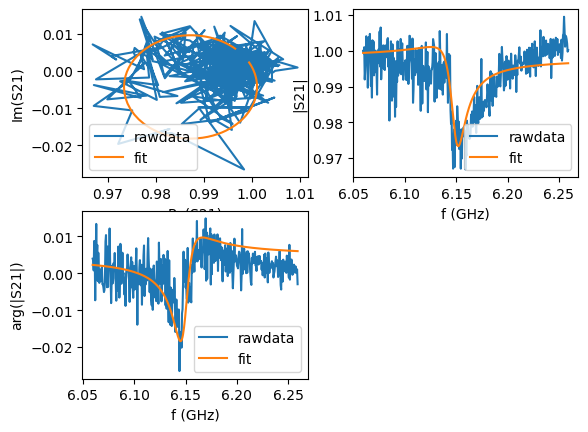

34
I1=-1.92 mA: f0=6148997851.847930 Hz, Ql=364


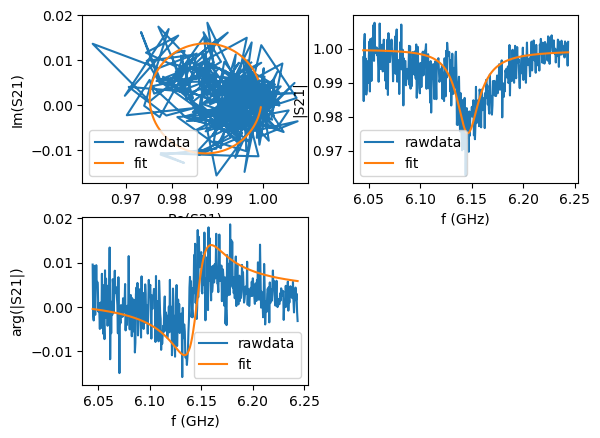

35
I1=-1.8 mA: f0=6145443477.597633 Hz, Ql=236


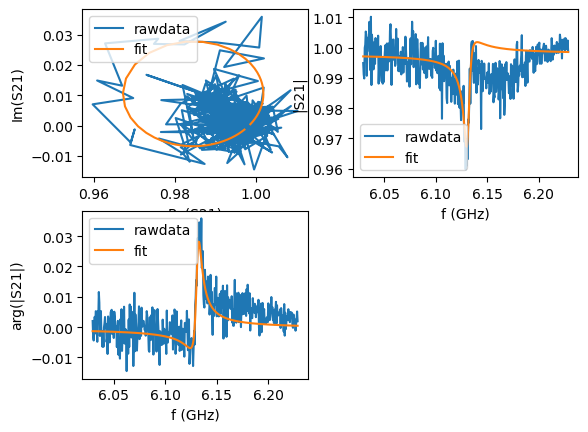

36
I1=-1.68 mA: f0=6131153106.267815 Hz, Ql=929


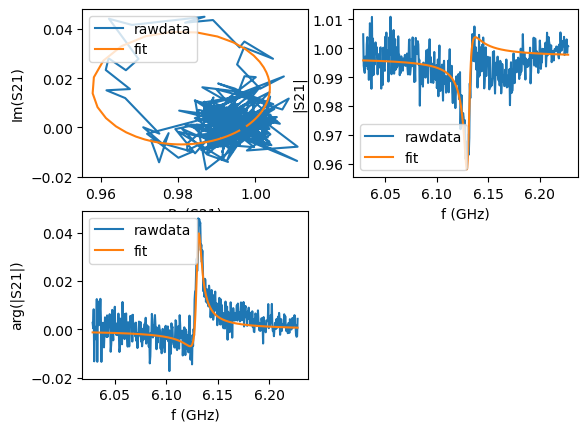

37
I1=-1.56 mA: f0=6130444236.417920 Hz, Ql=1.01e+03


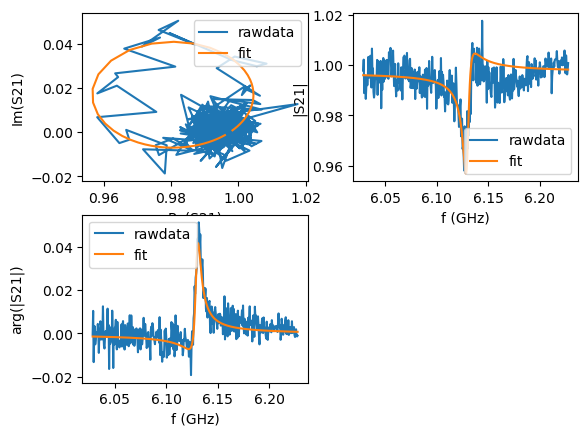

38
I1=-1.44 mA: f0=6129669890.484098 Hz, Ql=947


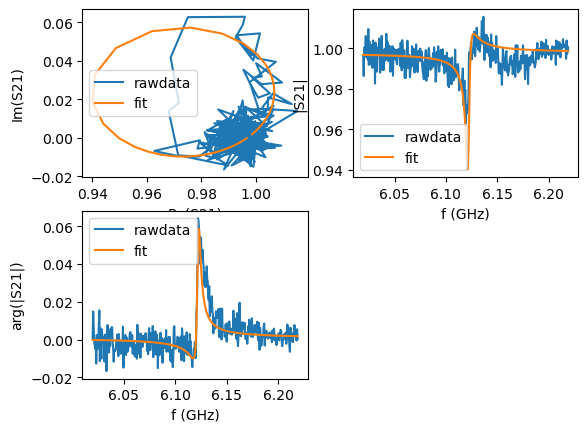

39
I1=-1.32 mA: f0=6122009615.740553 Hz, Ql=1.49e+03


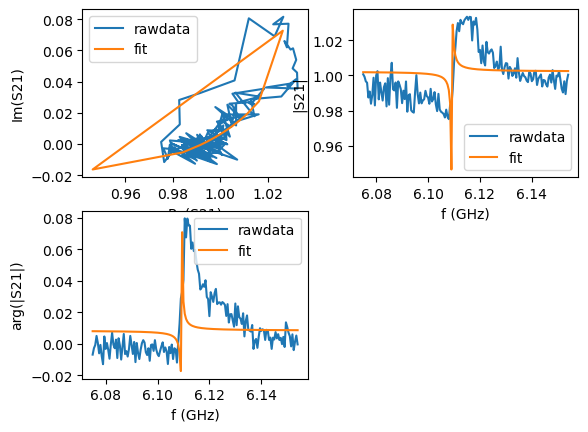

40
I1=-1.2 mA: f0=6109267285.320239 Hz, Ql=2.92e+04


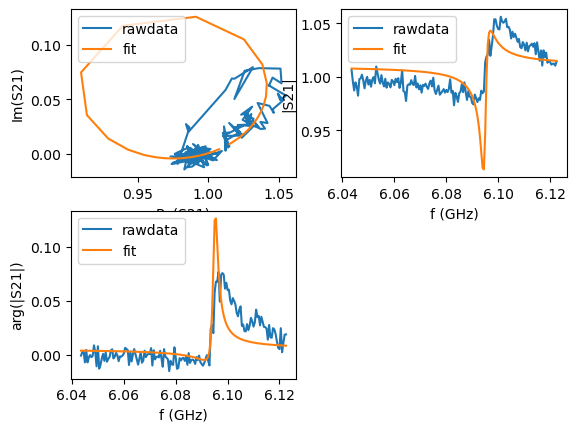

41
I1=-1.08 mA: f0=6095003007.711649 Hz, Ql=2.61e+03


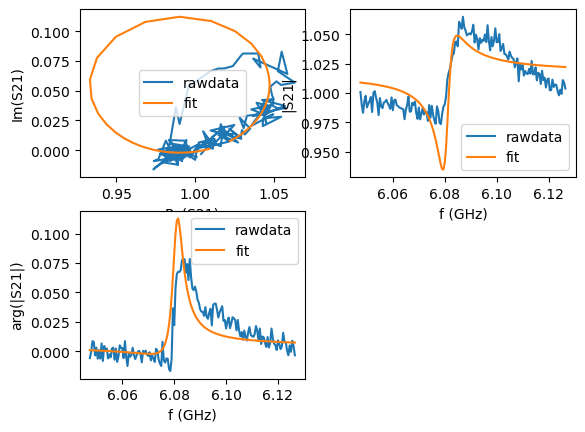

42
I1=-0.96 mA: f0=6080884125.392140 Hz, Ql=1.22e+03


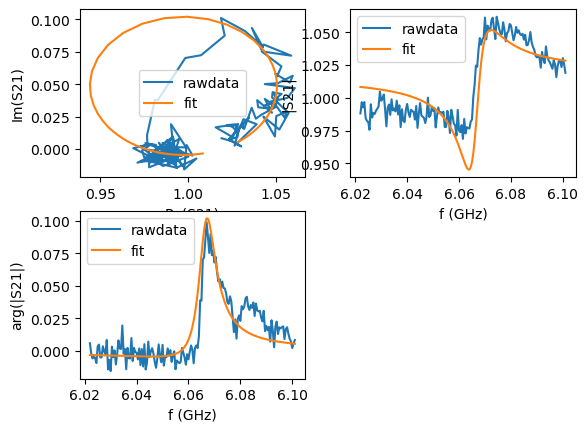

43
I1=-0.84 mA: f0=6066629199.829076 Hz, Ql=753


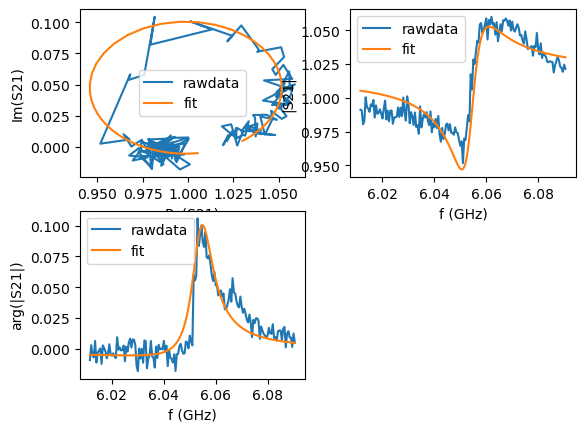

44
I1=-0.72 mA: f0=6054238329.095001 Hz, Ql=604


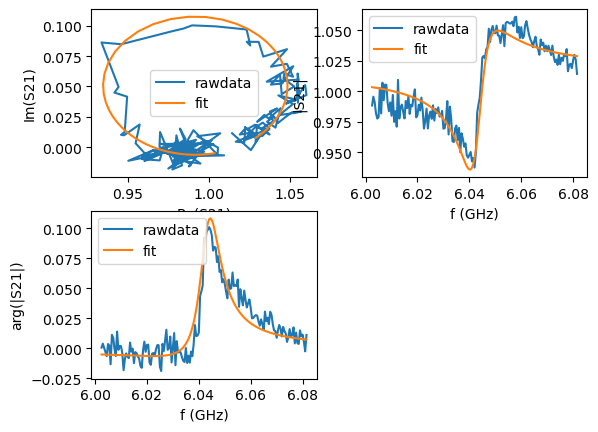

45
I1=-0.6 mA: f0=6043548156.946499 Hz, Ql=606


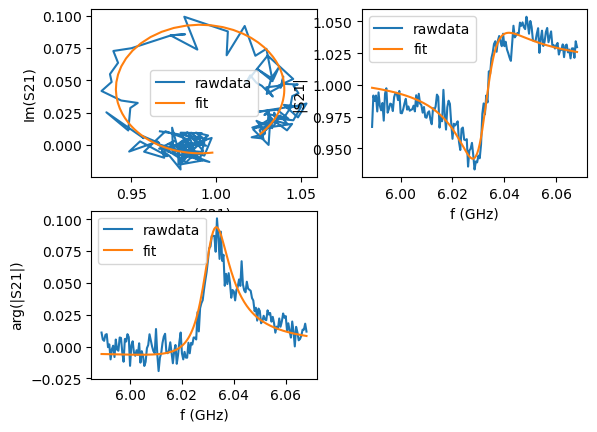

46
I1=-0.48 mA: f0=6032104068.882619 Hz, Ql=470


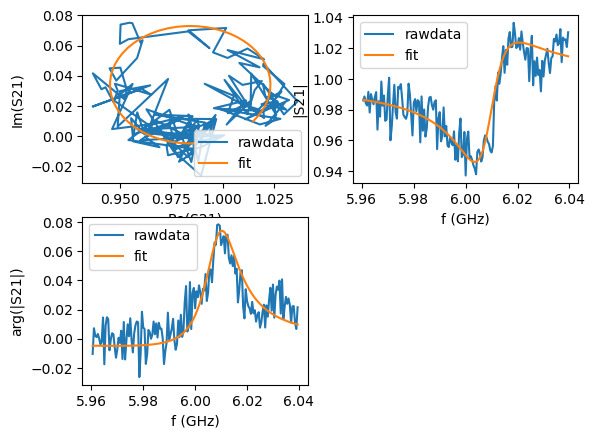

47
I1=-0.36 mA: f0=6009100483.765394 Hz, Ql=374


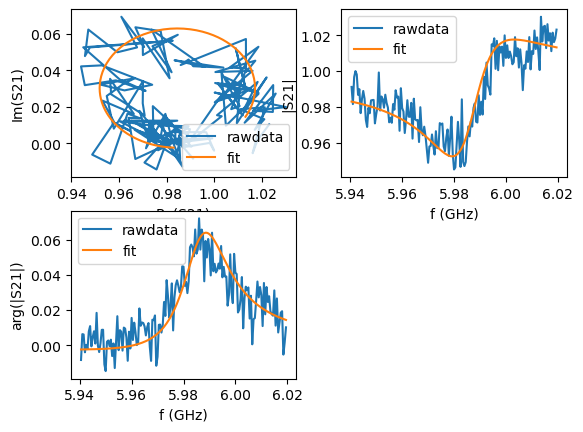

48
I1=-0.24 mA: f0=5986664230.617919 Hz, Ql=271


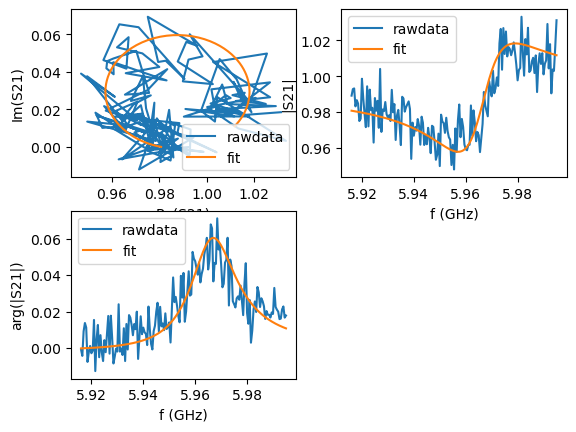

49
I1=-0.12 mA: f0=5966255389.509182 Hz, Ql=275


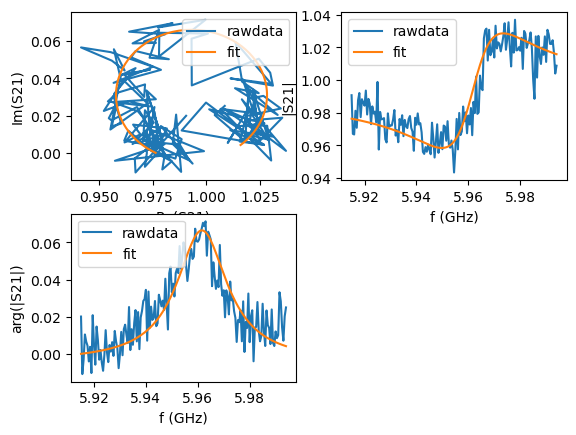

50
I1=0 mA: f0=5961997682.771344 Hz, Ql=252


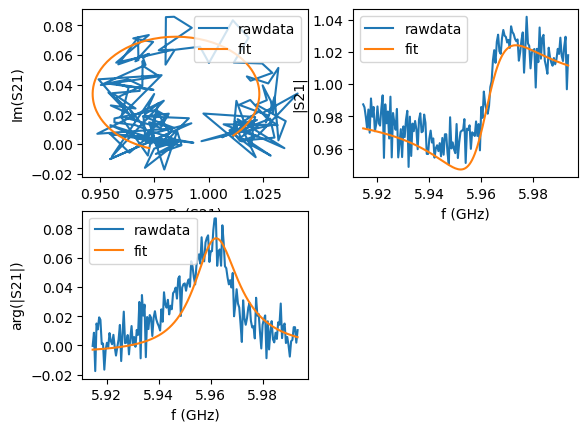

51
I1=0.12 mA: f0=5961882099.808620 Hz, Ql=281


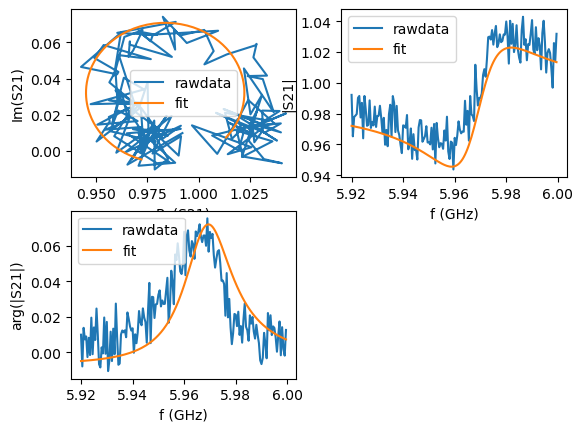

52
I1=0.24 mA: f0=5968946552.888039 Hz, Ql=260


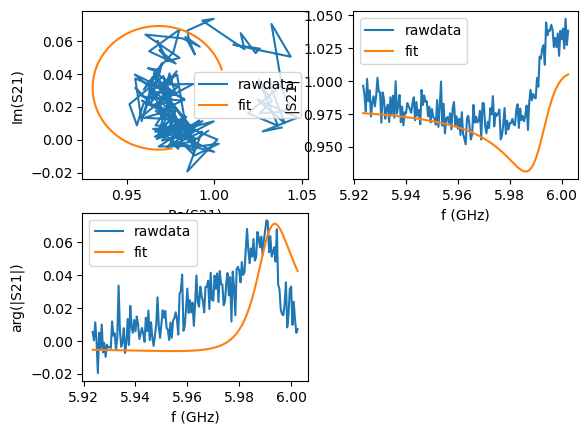

53
I1=0.36 mA: f0=5991932967.403934 Hz, Ql=332


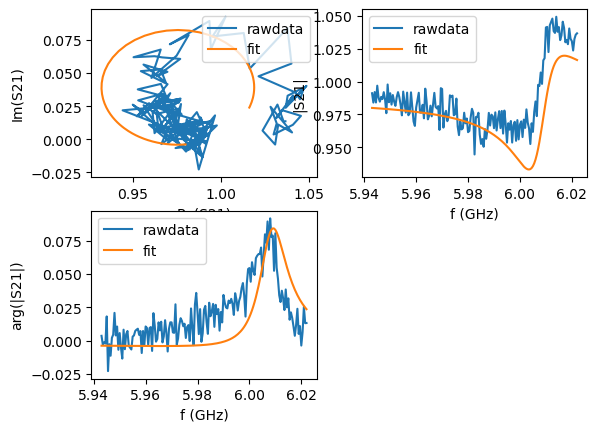

54
I1=0.48 mA: f0=6008490333.376484 Hz, Ql=455


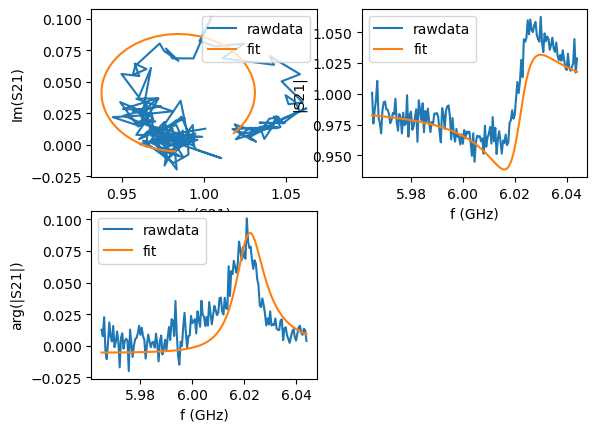

55
I1=0.6 mA: f0=6021844669.999358 Hz, Ql=436


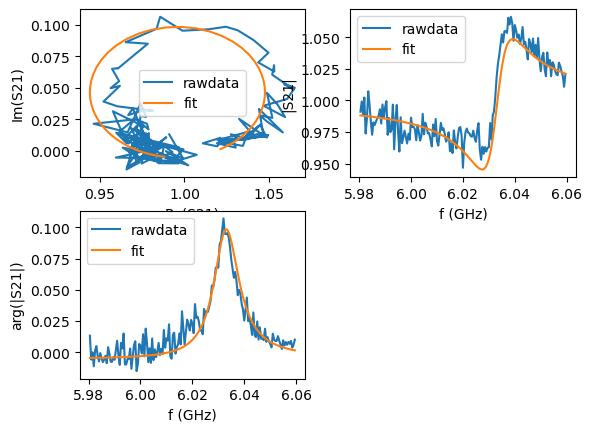

56
I1=0.72 mA: f0=6033151932.416088 Hz, Ql=510


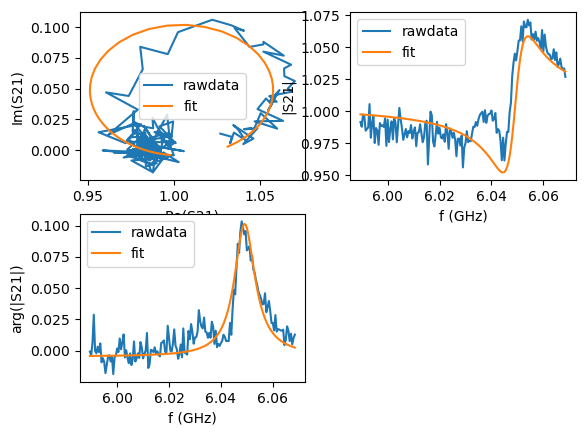

57
I1=0.84 mA: f0=6049293990.723444 Hz, Ql=628


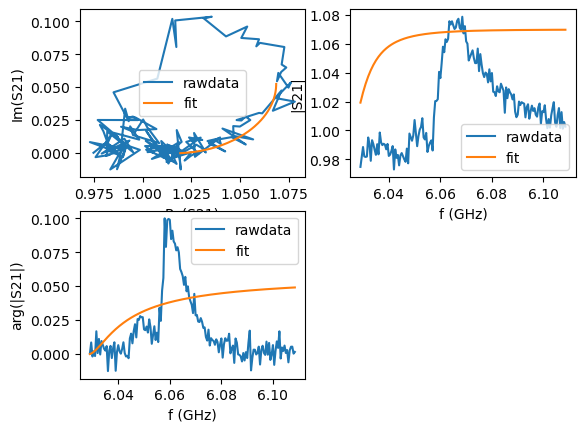

58
I1=0.96 mA: f0=6022022813.849831 Hz, Ql=-387


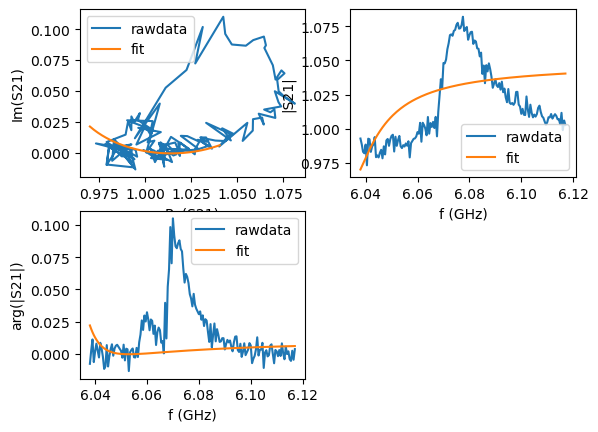

59
I1=1.08 mA: f0=6030107461.469926 Hz, Ql=-374


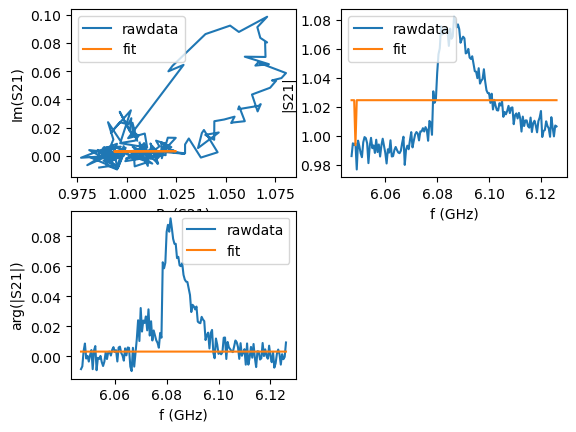

60
I1=1.2 mA: f0=6048500059.027950 Hz, Ql=1.91e+08


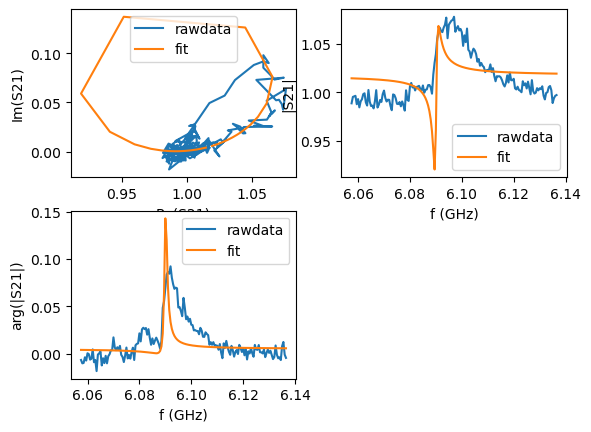

61
I1=1.32 mA: f0=6090069493.599498 Hz, Ql=4.62e+03


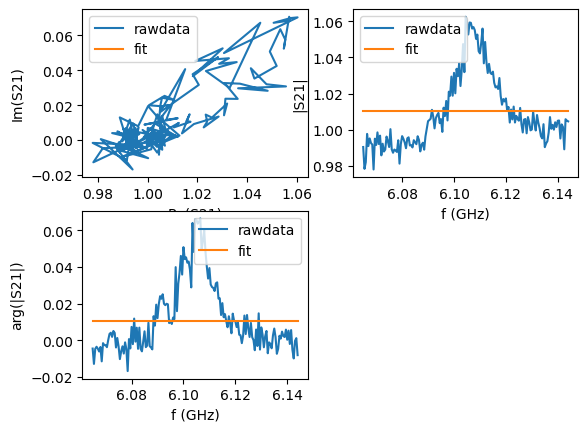

62
I1=1.44 mA: f0=-659360036618.921021 Hz, Ql=1.9e+09


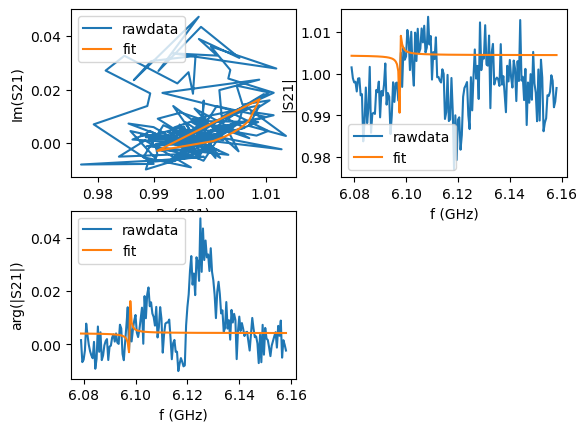

63
I1=1.56 mA: f0=6097724242.371099 Hz, Ql=3.2e+04


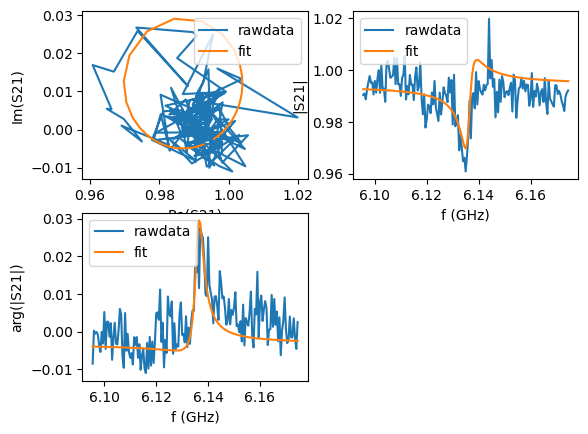

64
I1=1.68 mA: f0=6136206346.813120 Hz, Ql=1.55e+03


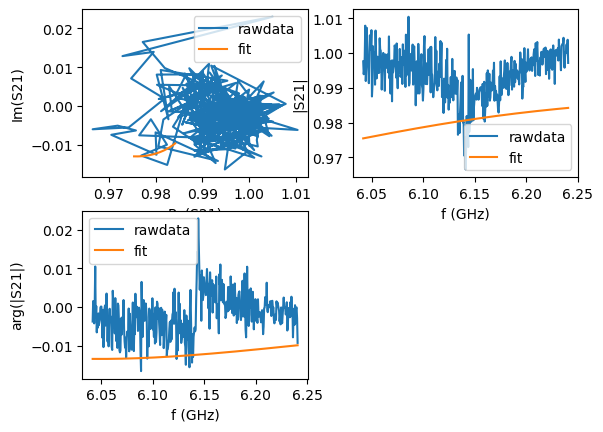

65
I1=1.8 mA: f0=5943944421.094256 Hz, Ql=-7.76


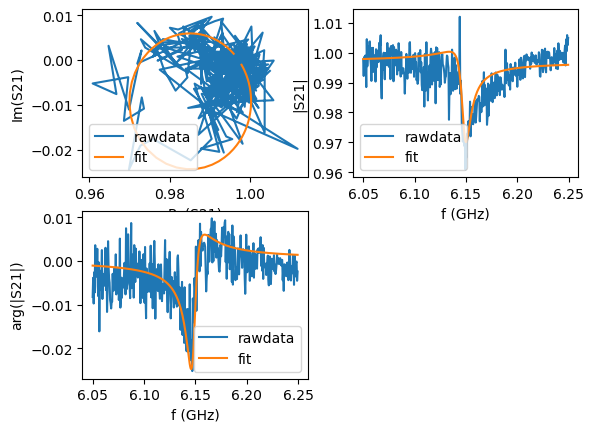

66
I1=1.92 mA: f0=6148299518.863537 Hz, Ql=594


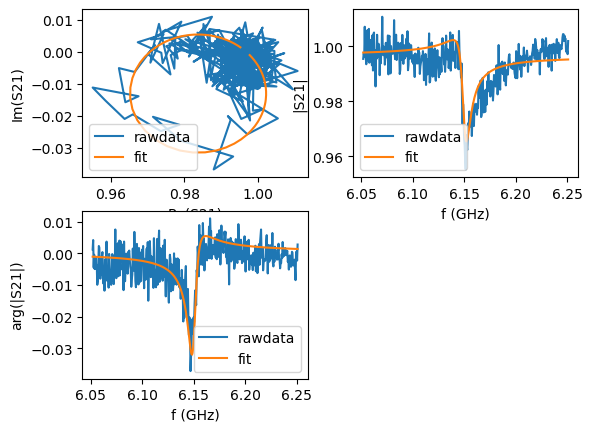

67
I1=2.04 mA: f0=6150191030.993643 Hz, Ql=651


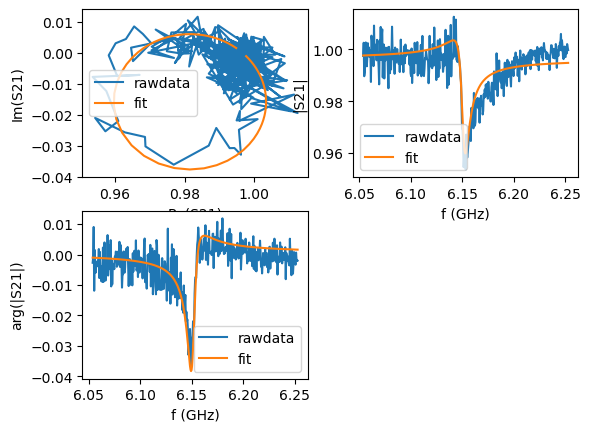

68
I1=2.16 mA: f0=6151205749.947228 Hz, Ql=696


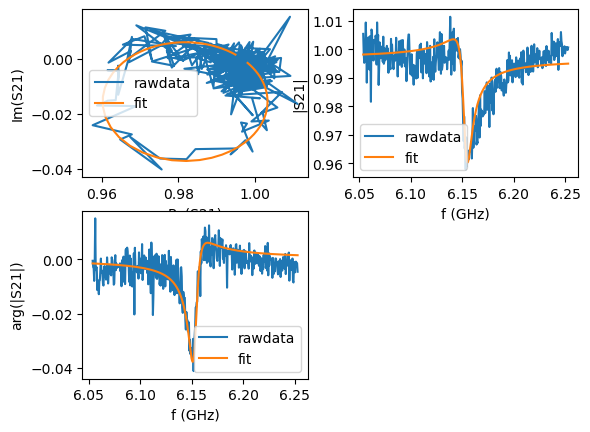

69
I1=2.28 mA: f0=6153065585.799916 Hz, Ql=606


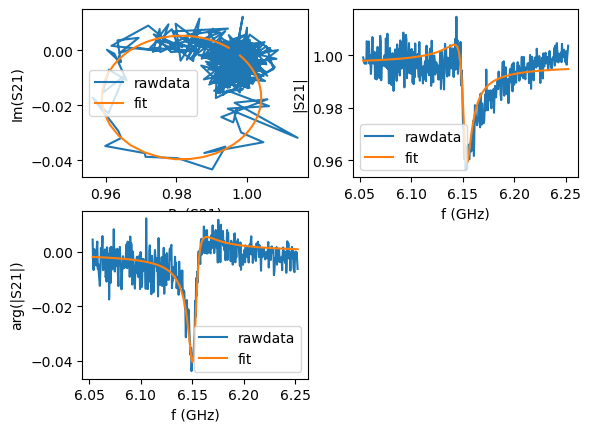

70
I1=2.4 mA: f0=6152080017.801289 Hz, Ql=658


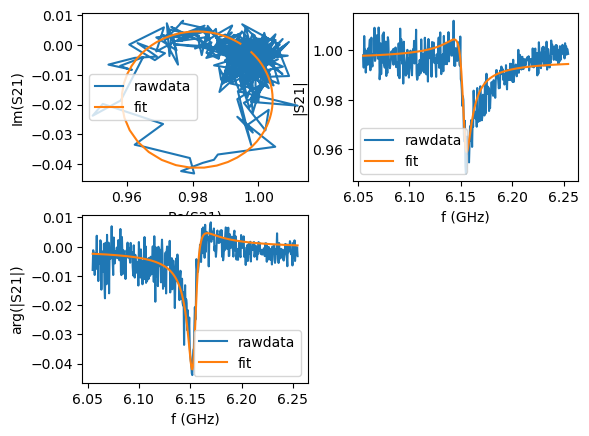

71
I1=2.52 mA: f0=6153517904.912470 Hz, Ql=641


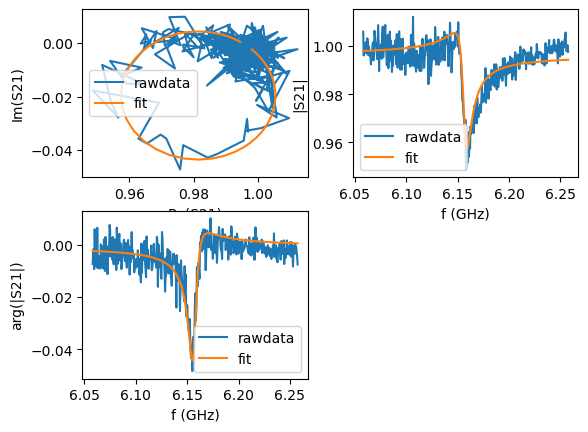

72
I1=2.64 mA: f0=6156713727.322117 Hz, Ql=631


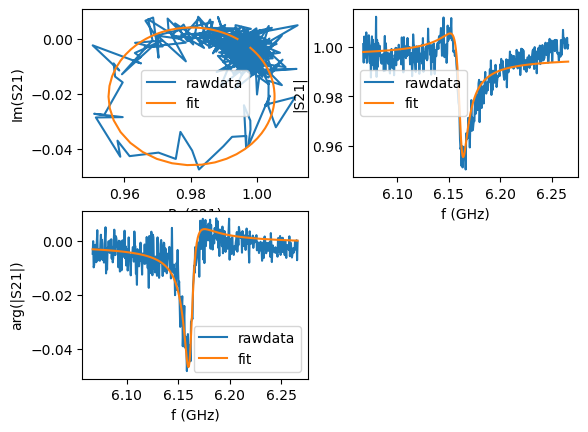

73
I1=2.76 mA: f0=6161631543.136841 Hz, Ql=615


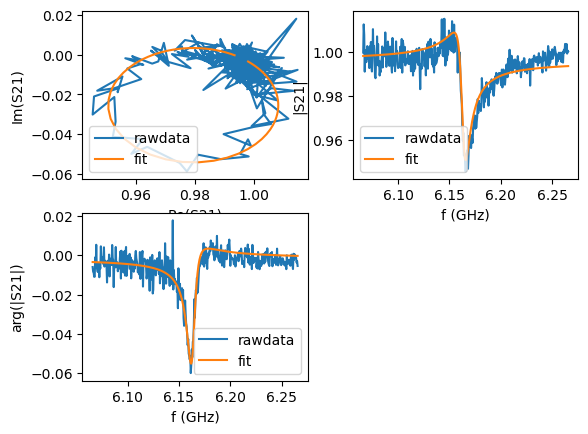

74
I1=2.88 mA: f0=6163163402.009195 Hz, Ql=640


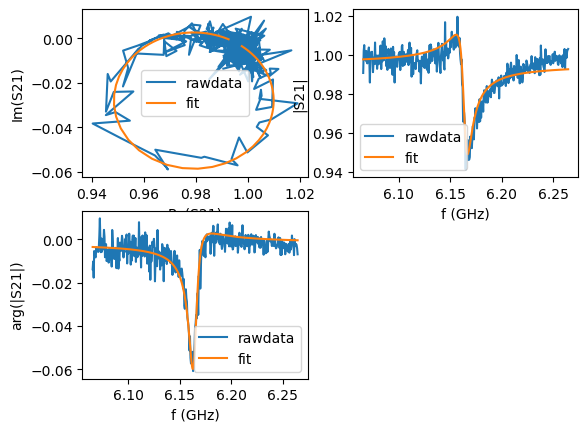

75
I1=3 mA: f0=6163991658.207529 Hz, Ql=638


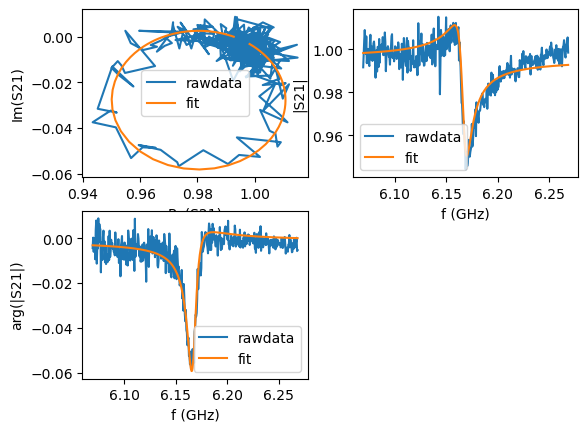

76
I1=3.12 mA: f0=6166918067.109906 Hz, Ql=588


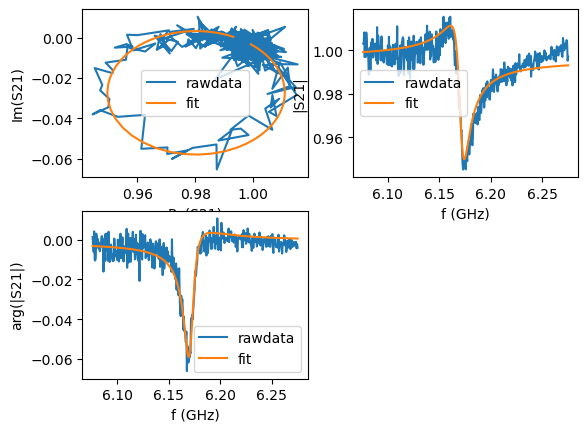

77
I1=3.24 mA: f0=6170731803.868723 Hz, Ql=532


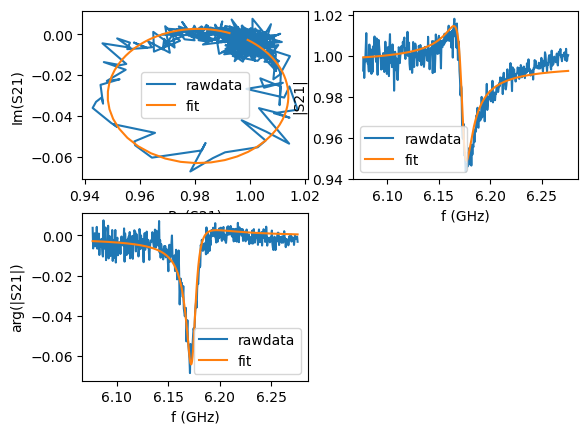

78
I1=3.36 mA: f0=6173267795.934889 Hz, Ql=549


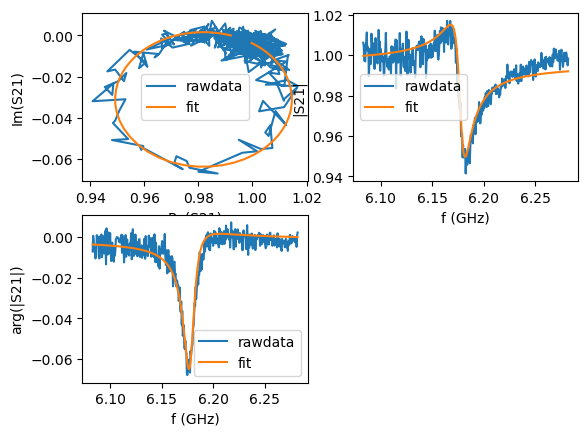

79
I1=3.48 mA: f0=6177699948.475446 Hz, Ql=478


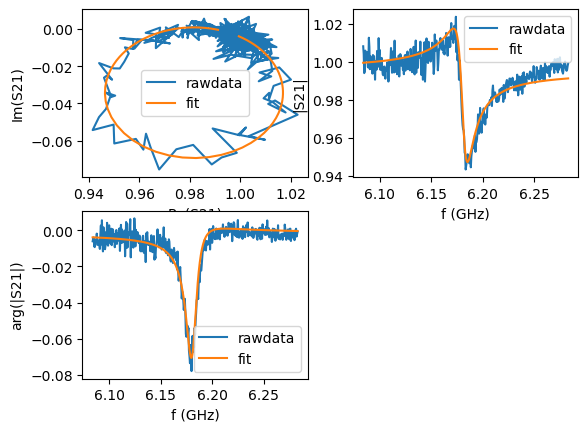

80
I1=3.6 mA: f0=6180857572.501540 Hz, Ql=486


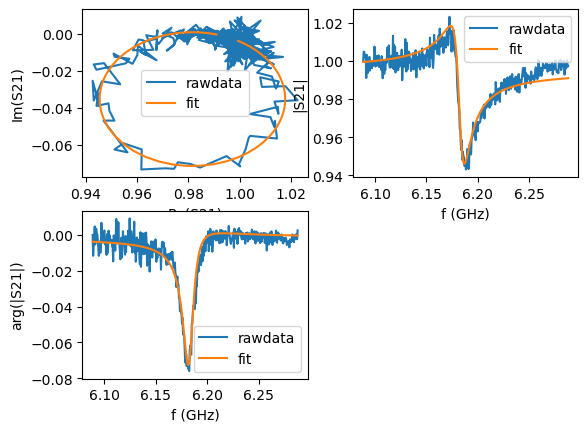

81
I1=3.72 mA: f0=6182541520.846893 Hz, Ql=490


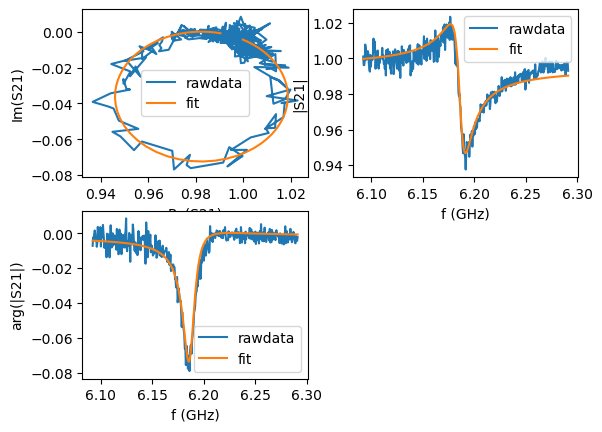

82
I1=3.84 mA: f0=6186314873.273199 Hz, Ql=447


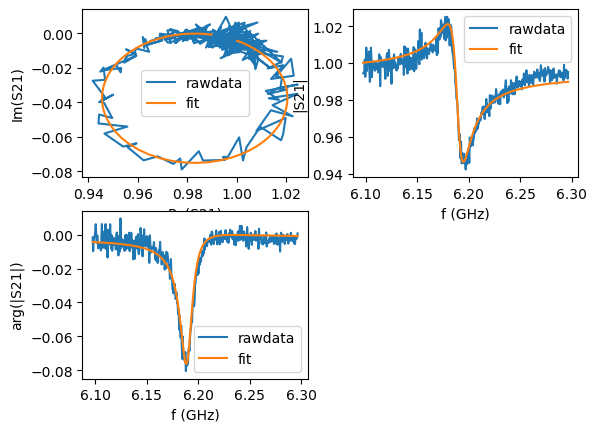

83
I1=3.96 mA: f0=6189269270.287083 Hz, Ql=426


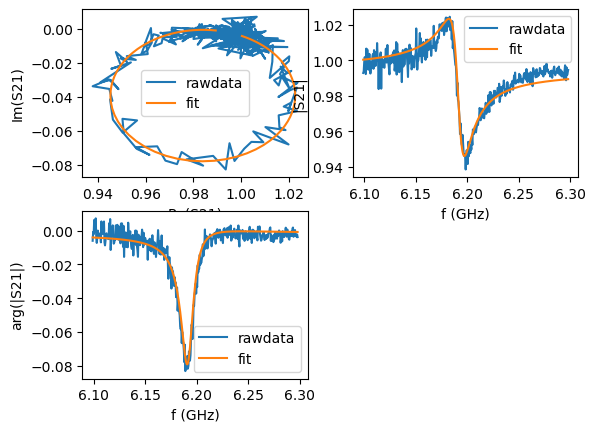

84
I1=4.08 mA: f0=6191510066.334475 Hz, Ql=421


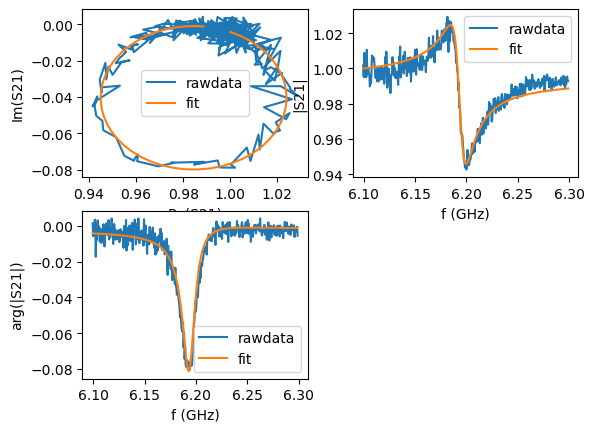

85
I1=4.2 mA: f0=6193619612.285228 Hz, Ql=415


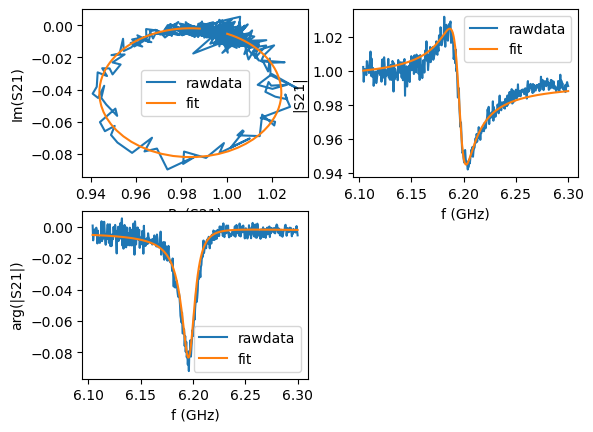

86
I1=4.32 mA: f0=6196230994.610241 Hz, Ql=404


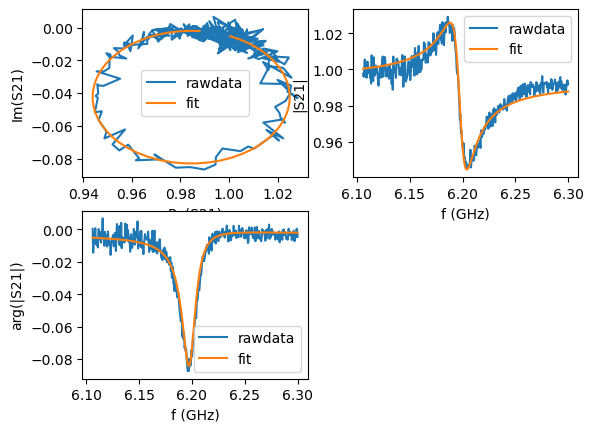

87
I1=4.44 mA: f0=6197688142.901064 Hz, Ql=398


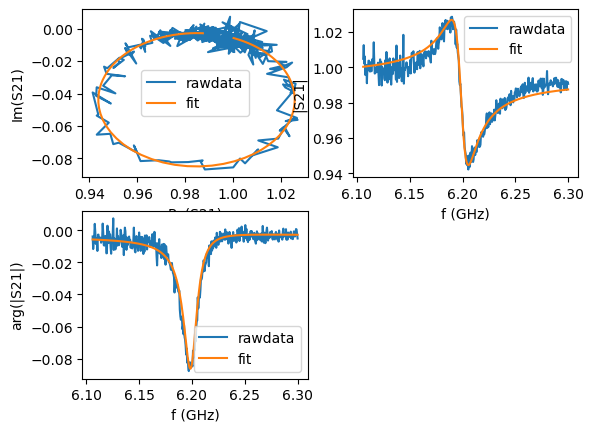

88
I1=4.56 mA: f0=6198992341.875807 Hz, Ql=396


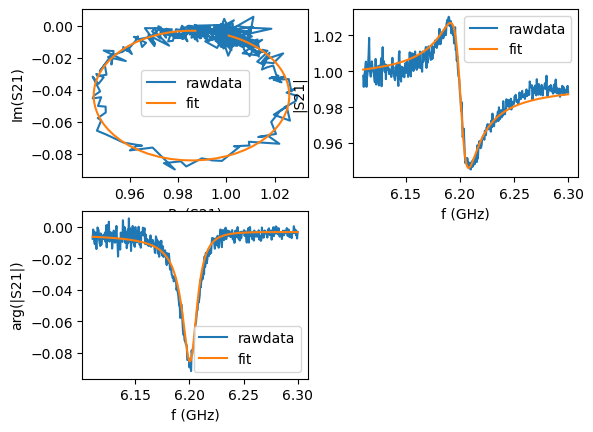

89
I1=4.68 mA: f0=6200931079.061475 Hz, Ql=373


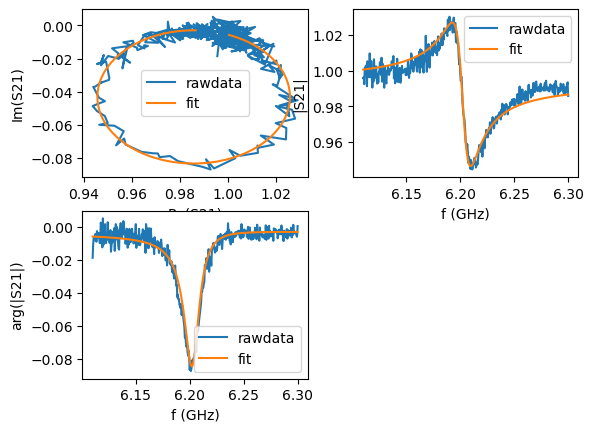

90
I1=4.8 mA: f0=6202381895.637525 Hz, Ql=366


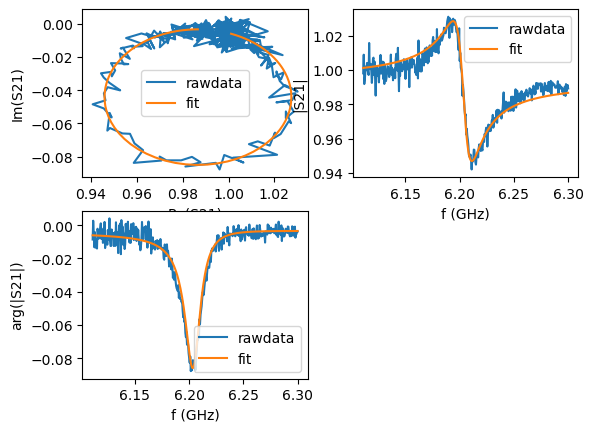

91
I1=4.92 mA: f0=6203707124.365126 Hz, Ql=360


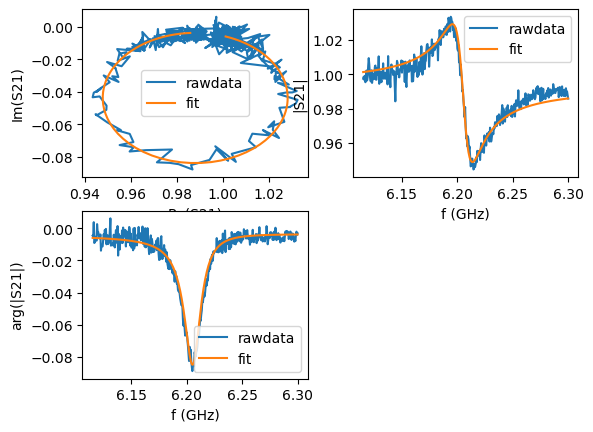

92
I1=5.04 mA: f0=6205406660.422300 Hz, Ql=344


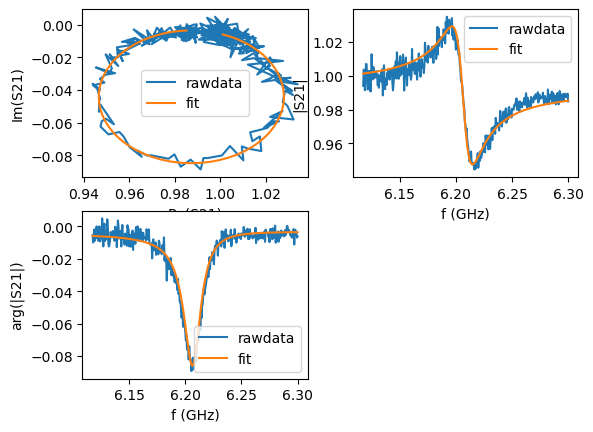

93
I1=5.16 mA: f0=6206602635.311779 Hz, Ql=339


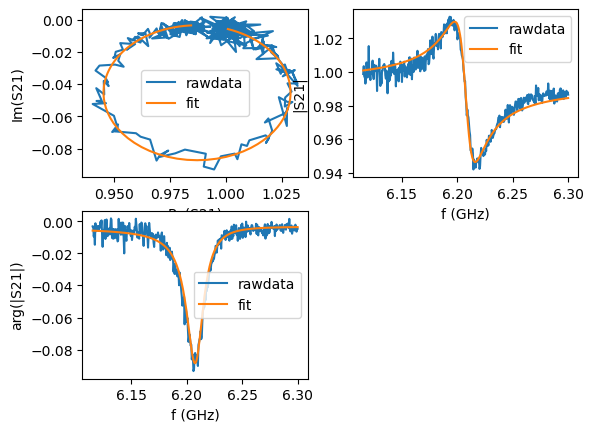

94
I1=5.28 mA: f0=6207640223.539592 Hz, Ql=335


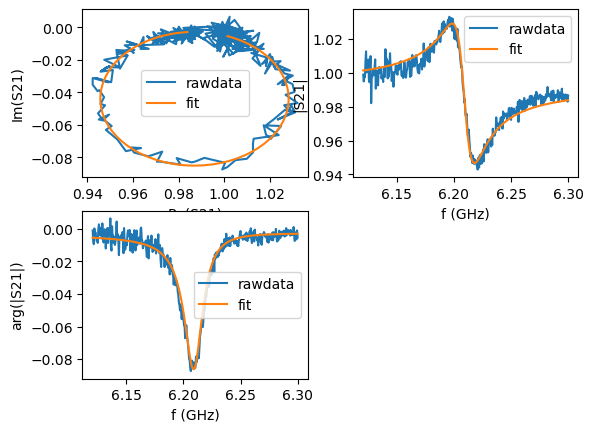

95
I1=5.4 mA: f0=6209129095.961622 Hz, Ql=317


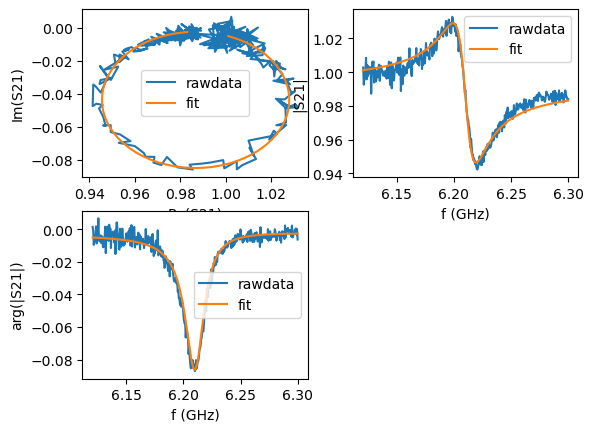

96
I1=5.52 mA: f0=6210096306.051076 Hz, Ql=309


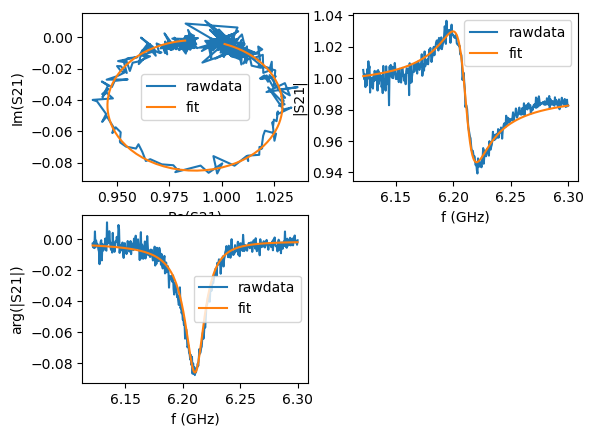

97
I1=5.64 mA: f0=6210727253.568110 Hz, Ql=303


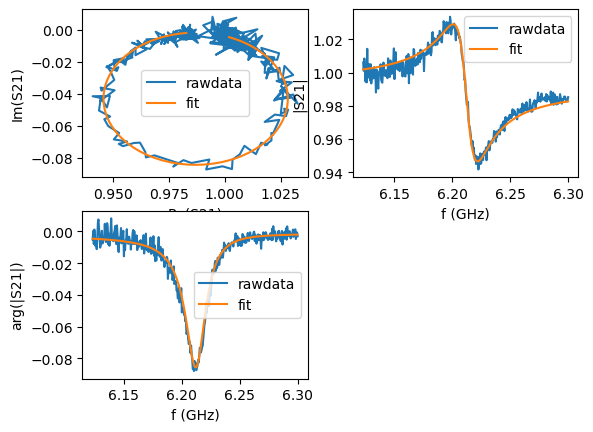

98
I1=5.76 mA: f0=6212237461.023731 Hz, Ql=296


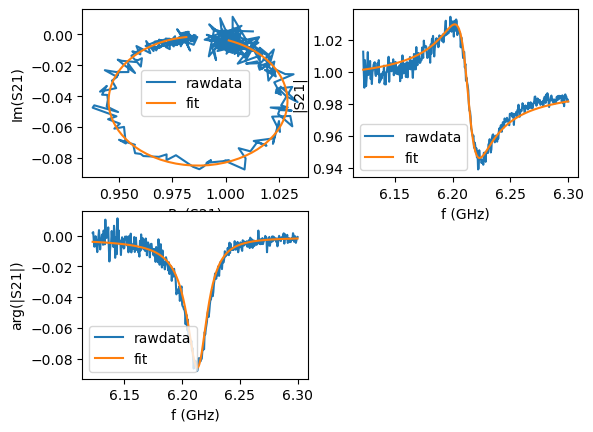

99
I1=5.88 mA: f0=6213279176.097042 Hz, Ql=289


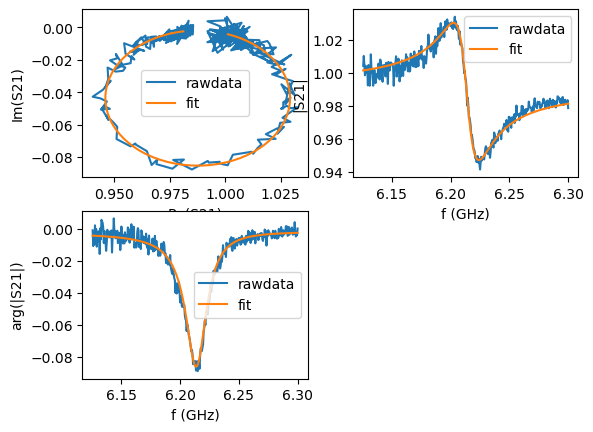

100
I1=6 mA: f0=6213679142.728821 Hz, Ql=288


In [8]:
for i in range(S21_Complex_full.shape[1]):
        if fit_results_dict[i] is not None:
            ports_dict[i].plotall()
            print(i)
            print(f"I1={I1_full[i]:.3g} mA: f0={fit_results_dict[i]['fr']:.6f} Hz, Ql={fit_results_dict[i]['Ql']:.3g}")

In [33]:
import inspect
print(inspect.signature(circuit.notch_port.autofit))

(self, electric_delay: float | None = None, fcrop: tuple[float, float] | None = None, Ql_guess: float | None = None, fr_guess: float | None = None) -> None


In [103]:
print(sorted(fit_results_dict[0].keys()))

['Qc_dia_corr', 'Qi_dia_corr', 'Qi_dia_corr_err', 'Qi_no_corr', 'Qi_no_corr_err', 'Ql', 'Ql_err', 'absQc', 'absQc_err', 'chi_square', 'fr', 'fr_err', 'phi0', 'phi0_err', 'theta0']


In [9]:
import numpy as np

fr = np.full(len(fit_results_dict), np.nan)
Qi = np.full(len(fit_results_dict), np.nan)
Qc = np.full(len(fit_results_dict), np.nan)
Ql = np.full(len(fit_results_dict), np.nan)

for i, r in enumerate(fit_results_dict.values()):
    if r is None:
        continue
    fr[i] = r['fr']
    Qi[i] = r.get('Qi_dia_corr', r.get('Qi'))   # key names vary slightly by version — check port.fitresults.keys()
    Qc[i] = r.get('Qc_dia_corr', r.get('Qc'))
    Ql[i] = r['Ql']
    Ql[39] = Ql[38]
    Ql[43] = Ql[44]

In [10]:
for i in [0, 20]:
    r = fit_results_dict[i]
    print(i, {k: r[k] for k in ('fr','fr_err','Ql','Ql_err','phi0','phi0_err','theta0','chi_square')})

0 {'fr': np.float64(6215704744.007041), 'fr_err': np.float64(323754.57123284705), 'Ql': np.float64(275.2456169297151), 'Ql_err': np.float64(8.294005275473046), 'phi0': np.float64(1.495977682681652), 'phi0_err': np.float64(0.0224823602324242), 'theta0': np.float64(-1.6456149709081416), 'chi_square': np.float64(4.927001827846718e-05)}
20 {'fr': np.float64(6187754524.392284), 'fr_err': np.float64(288969.3127477273), 'Ql': np.float64(451.6985773503239), 'Ql_err': np.float64(18.062336588415814), 'phi0': np.float64(1.2599877701586197), 'phi0_err': np.float64(0.0326328958768167), 'theta0': np.float64(-1.881604883431173), 'chi_square': np.float64(4.692110640654381e-05)}


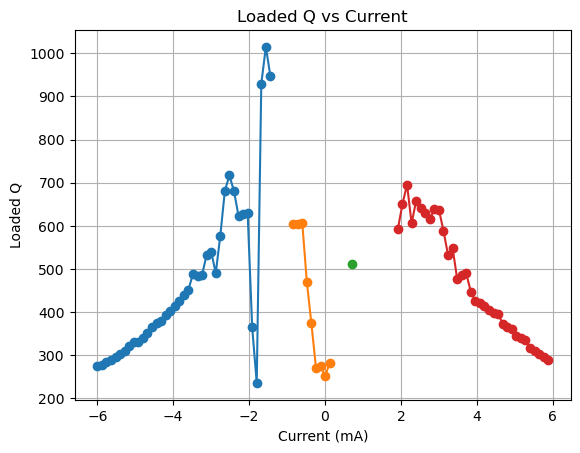

In [25]:
plt.plot(I1_full[0:39], Ql[0:39], 'o-')
plt.plot(I1_full[43:52], Ql[43:52], 'o-')
plt.plot(I1_full[56:57], Ql[56:57], 'o-')
plt.plot(I1_full[66:100], Ql[66:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
plt.show()

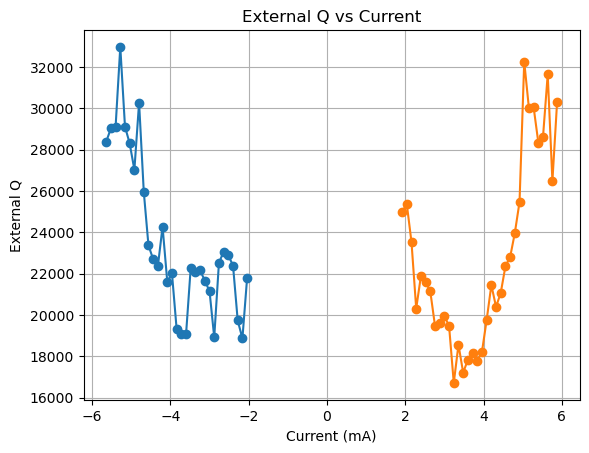

In [21]:
plt.plot(I1_full[3:34], Qc[3:34], 'o-')
# plt.plot(I1_full[43:52], Qc[43:52], 'o-')
# plt.plot(I1_full[56:57], Qc[56:57], 'o-')
plt.plot(I1_full[66:100], Qc[66:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('External Q')
plt.title('External Q vs Current')
plt.grid(True)
plt.show()

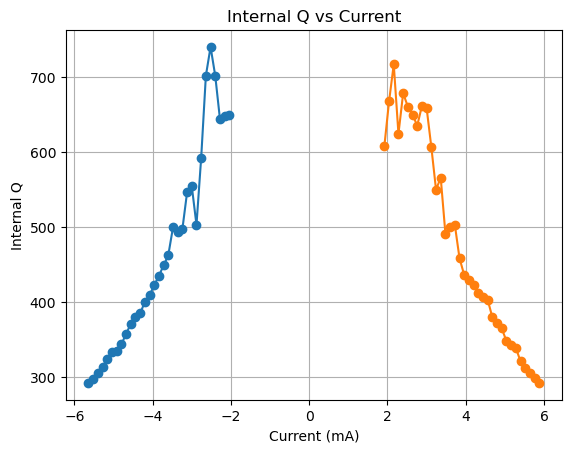

In [24]:
plt.plot(I1_full[3:34], Qi[3:34], 'o-')
# plt.plot(I1_full[43:52], Qc[43:52], 'o-')
# plt.plot(I1_full[56:57], Qc[56:57], 'o-')
plt.plot(I1_full[66:100], Qi[66:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Internal Q')
plt.title('Internal Q vs Current')
plt.grid(True)
plt.show()

In [91]:
S21_Complex_2 = S21_Complex_full[:, 89:101]
I1_2 = I1_full[89:101]

# for i in range(S21_Complex_2.shape[1]):
#     print(i)
#     plt.plot(np.real(S21_Complex_2[:, i]), np.imag(S21_Complex_2[:, i]), 'o-')
#     plt.xlabel('Real')
#     plt.ylabel('Imaginary')
#     plt.title('S21 Complex Plane')
#     plt.show()


In [92]:
fit_results_dict_2 = {}
ports_dict_2 = {}   # optional, if you want to re-plot a specific trace later without refitting
window_halfwidth = 100e6 
for i in range(S21_Complex_2.shape[1]):
    mask = np.abs(Freq - f0_smooth[i]) < window_halfwidth
    f_sub = Freq[mask]
    s_sub = S21_Complex_2[mask, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        port_i.autofit()
        fit_results_dict_2[i] = port_i.fitresults
        ports_dict_2[i] = port_i
    except Exception as e:
        print(f"I1={I1_2[i]:.3g} mA: fit failed ({e})")
        fit_results_dict_2[i] = None

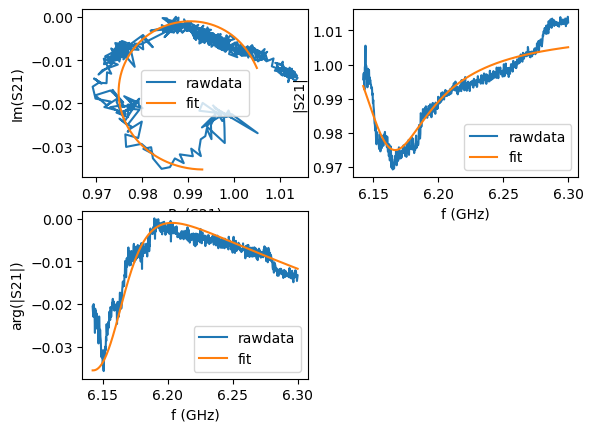

0
I1=5.46 mA: f0=6156469401.127153 Hz, Ql=98.2


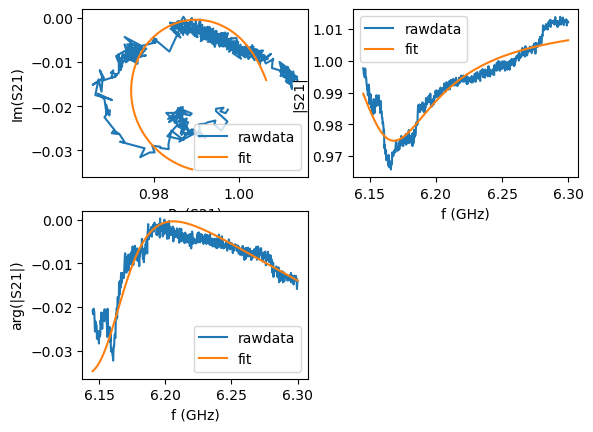

1
I1=5.6 mA: f0=6155770870.543033 Hz, Ql=83.6


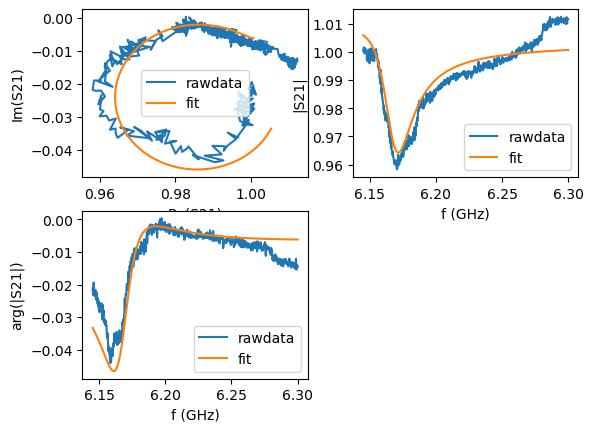

2
I1=5.74 mA: f0=6167296366.686216 Hz, Ql=241


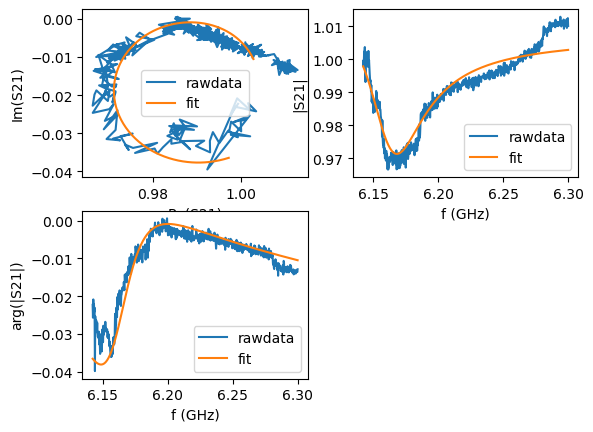

3
I1=5.88 mA: f0=6160330792.482904 Hz, Ql=126


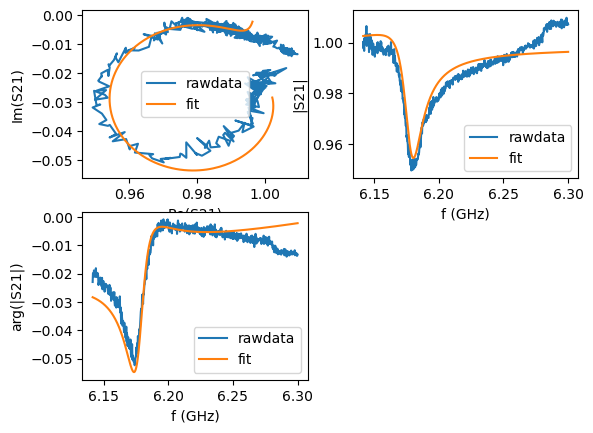

4
I1=6.02 mA: f0=6177619099.489537 Hz, Ql=375


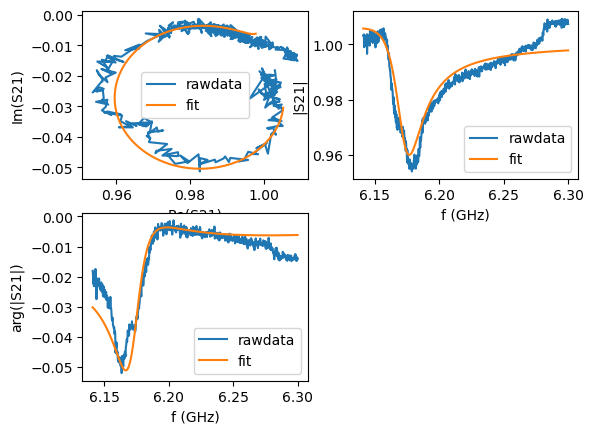

5
I1=6.16 mA: f0=6172431555.124295 Hz, Ql=253


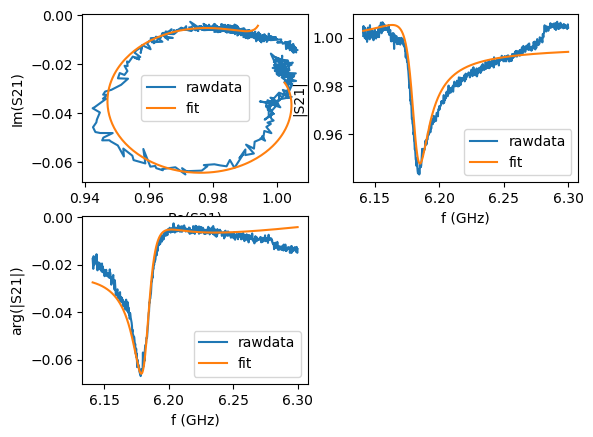

6
I1=6.3 mA: f0=6181795440.521768 Hz, Ql=402


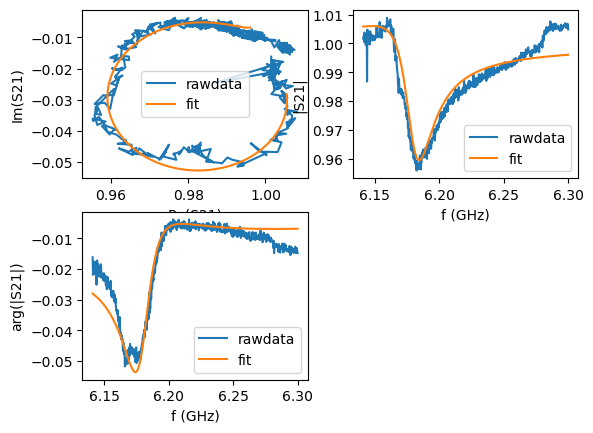

7
I1=6.44 mA: f0=6179404316.095573 Hz, Ql=245


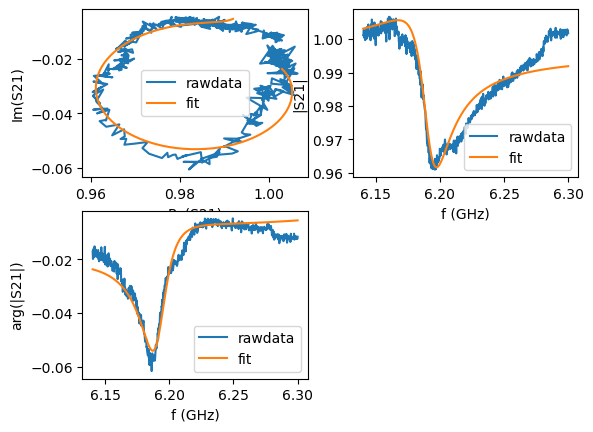

8
I1=6.58 mA: f0=6190878340.750670 Hz, Ql=249


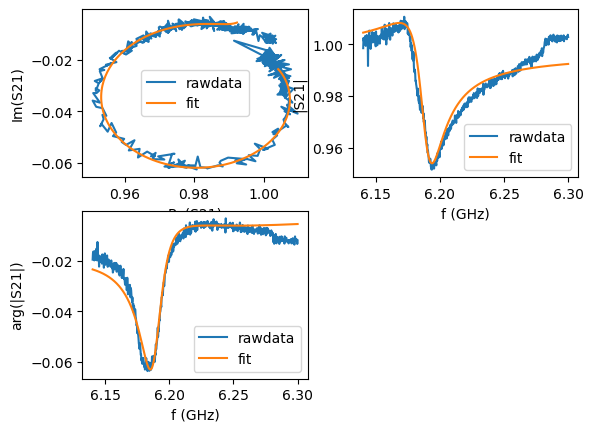

9
I1=6.72 mA: f0=6188361648.729506 Hz, Ql=295


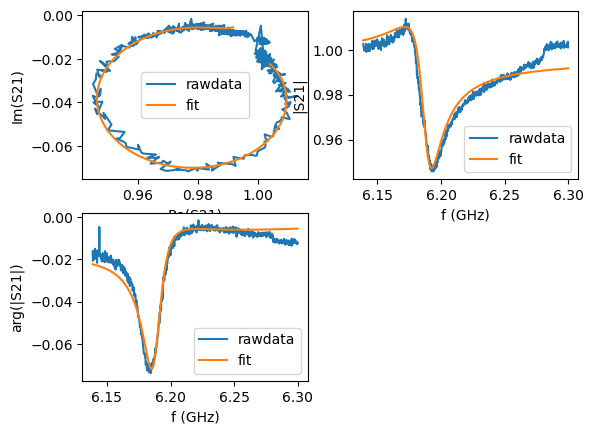

10
I1=6.86 mA: f0=6187627259.513644 Hz, Ql=346


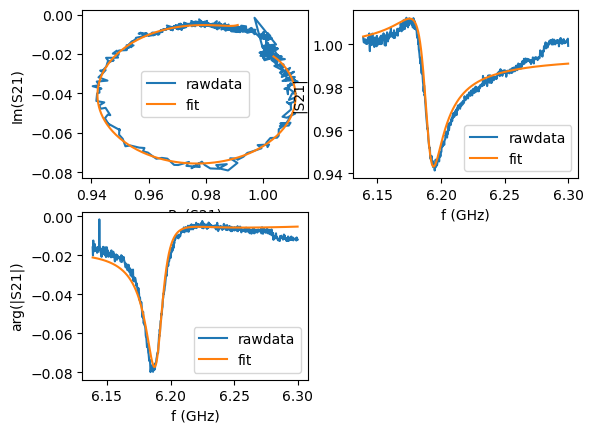

11
I1=7 mA: f0=6189469055.044045 Hz, Ql=382


In [93]:
for i in range(S21_Complex_2.shape[1]):
        if fit_results_dict_2[i] is not None:
            ports_dict_2[i].plotall()
            print(i)
            print(f"I1={I1_2[i]:.3g} mA: f0={fit_results_dict_2[i]['fr']:.6f} Hz, Ql={fit_results_dict_2[i]['Ql']:.3g}")

In [94]:
fr_2 = np.full(len(fit_results_dict_2), np.nan)
Qi_2 = np.full(len(fit_results_dict_2), np.nan)
Qc_2 = np.full(len(fit_results_dict_2), np.nan)
Ql_2 = np.full(len(fit_results_dict_2), np.nan)

for i, r in enumerate(fit_results_dict_2.values()):
    if r is None:
        continue
    fr_2[i] = r['fr']
    Qi_2[i] = r.get('Qi_dia_corr', r.get('Qi'))   # key names vary slightly by version — check port.fitresults.keys()
    Qc_2[i] = r.get('Qc_dia_corr', r.get('Qc'))
    Ql_2[i] = r['Ql']

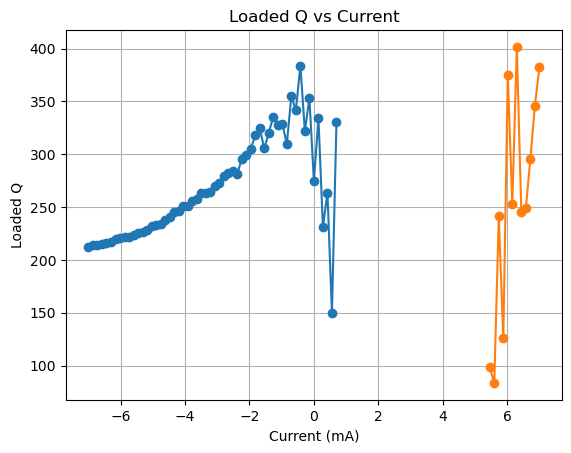

In [96]:
plt.plot(I1, Ql, 'o-')
plt.plot(I1_2, Ql_2, 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
plt.show()